# WD-GPR-SR — Wide-and-Deep Sparse GP with Uncertainty-Weighted Symbolic Residuals

This is the **proposed main model** for the battery SOH project. It uses the same cycle-level `data/unified.parquet`, feature contract, train-only preprocessing and sorted Leave-One-Cell-Out (LOCO) cell folds as the 13 baseline notebooks.

**Target:** `soh_pct` in SOH percentage points. **Supervised sources:** NASA + CALCE. Mobile2Mobile remains EDA-only and is not mixed into the labelled regression task.

**Outputs:**
- `WD-GPR-SR/results/`: OOF predictions, per-fold/per-cell/per-seed metrics, ablations, XAI tables/plots, training curves, baseline comparison and hardware benchmark report.
- `models/wd_gpr_sr.joblib`: final all-labelled-cell inference bundle.
- `models/optimized/wd_gpr_sr/`: edge component exports (ONNX branch extractors, inducing-point/GP parameters, equation JSON/C and metadata).

The notebook does **not** overwrite any baseline model, baseline metric or baseline prediction file. It defaults to the three-seed protocol required by the project PDF. A one-seed smoke run is available by changing `RUN_SEEDS` while debugging; do not report that as the final statistical result.

## 1. Requirements from the project PDF and method

This notebook implements the WD-GPR-SR requirements from the project brief:

1. Public NASA + CALCE battery data; current validated export is already cycle-level.
2. Fixed, reproducible sorted-cell LOCO evaluation; the same held-out cell order as the baseline notebooks.
3. No leakage: imputation, one-hot encoding, numeric scaling and target scaling are fit on the outer training cells only. The held-out cell is used only for final evaluation. Symbolic residual training uses **inner GroupKFold cross-fitted GP residuals from outer-training cells only**.
4. A wide-and-deep covariance: a learned wide linear projection/kernel plus a deep neural feature extractor and ARD-RBF kernel, trained jointly by the sparse variational evidence lower bound (ELBO).
5. An uncertainty-guided symbolic residual correction trained with an uncertainty-emphasizing fitness weight.
6. At least three random seeds (42, 43, 44), with mean and standard deviation reported across seeds. LOCO cell assignments remain identical across seeds.
7. Accuracy and uncertainty metrics; component ablations; SHAP, LIME, PDP, ICE, ARD length-scale relevance, symbolic equation sensitivities and explanation-consistency analysis.
8. Model, results and edge components saved to project folders. The hardware benchmark cell measures 1,000 warmed-up inference batches on an actual Jetson, when run there. Off-device Jetson fields remain `NaN`.

### Mathematical formulation

Let \(x\in\mathbb R^d\) be a preprocessed cycle-level feature vector. A learned wide map \(w_\psi(x)\) and a nonlinear deep map \(\phi_\theta(x)\) define the additive kernel

\[
k_{WD}(x,x') = \sigma_w^2\, w_\psi(x)^\top w_\psi(x')
+ \sigma_d^2\exp\left[-\frac12\sum_{j=1}^{q}
\frac{(\phi_\theta(x)_j-\phi_\theta(x')_j)^2}{\ell_j^2}\right].
\]

A sparse variational GP with inducing inputs \(Z\) learns its variational posterior by maximizing

\[
\mathcal L_{ELBO}=\sum_{i=1}^{N}\mathbb E_{q(f_i)}[\log p(y_i\mid f_i)]
-\mathrm{KL}[q(u)\Vert p(u)].
\]

Inner cell-group cross-fitting produces residual targets
\(e_i=y_i-\mu_{GP}^{(-g_i)}(x_i)\) and predictive standard deviations
\(s_i=\sigma_{GP}^{(-g_i)}(x_i)\), where the inner GP never saw the cell containing row \(i\).
The symbolic model receives selected standardized features and normalized uncertainty:

\[
\tilde x_i=[x_{i,j_1},\ldots,x_{i,j_k},\operatorname{clip}(s_i/s_0,0.05,20)],
\qquad
\hat r=\arg\min_r\sum_i \omega_i(e_i-r(\tilde x_i))^2+\lambda\,\Omega(r),
\]

with \(\omega_i=\operatorname{clip}(s_i/s_0,0.25,4)\) and a gplearn parsimony penalty \(\Omega(r)\). This is an *uncertainty-emphasizing* weighting choice: higher-GP-uncertainty training residuals receive more emphasis when fitting the correction. It is a modelling choice, not a general calibration guarantee.

The final predictor and uncertainty approximation are

\[
\hat y(x)=\mu_{GP}(x)+r(\tilde x),\qquad
s_{total}(x)=\sqrt{s_{GP}(x)^2+s_{SR,cal}^2},
\]

where \(s_{SR,cal}\) is estimated on an inner cross-fitted calibration subset that is held out from symbolic equation fitting. The empirical PICP/MPIW/NLL on outer LOCO cells determine whether this uncertainty approximation is calibrated; do not assume nominal 95% coverage.

## 2. Dependencies

Run once in the notebook environment. The install cell deliberately does not replace your existing CUDA-enabled PyTorch build; install a PyTorch version compatible with your machine/JetPack separately only if PyTorch is missing.

In [13]:
%pip install -q numpy pandas scipy scikit-learn matplotlib joblib pyarrow psutil gpytorch gplearn shap lime onnx

Note: you may need to restart the kernel to use updated packages.


## 3. Imports, paths, reproducibility and compute configuration

In [14]:
from pathlib import Path
import os, re, json, time, random, warnings, math, numbers, platform, subprocess, threading, ctypes, shutil, resource, copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from scipy.stats import spearmanr

try:
    import psutil
except ImportError:
    psutil = None

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
except ImportError as exc:
    raise ImportError('WD-GPR-SR requires PyTorch. Install a build compatible with this machine first.') from exc

try:
    import gpytorch
except ImportError as exc:
    raise ImportError('Install GPyTorch with `%pip install gpytorch`.') from exc

try:
    from gplearn.genetic import SymbolicRegressor
    from gplearn.fitness import make_fitness
except ImportError as exc:
    raise ImportError('Install gplearn with `%pip install gplearn`.') from exc

RANDOM_SEED = 42
RUN_SEEDS = [42, 43, 44]
TARGET = 'soh_pct'
EXPECTED_CELL_COUNT = 47
DATA_DIR_OVERRIDE = None

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
BATCH_SIZE = 256
LATENT_DIM = 12
NUM_INDUCING = 64
INNER_NUM_INDUCING = 40
CROSSFIT_FOLDS = 3
INNER_GP_EPOCHS = 18
FINAL_GP_EPOCHS = 35
BRANCH_ABLATION_EPOCHS = 20
GP_LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-5
MAX_SR_FEATURES = 6
SR_POPULATION_SIZE = 160
SR_GENERATIONS = 10
SR_PARSIMONY = 0.002
PERMUTATION_FEATURE_CAP = 12

SMOKE_TEST = False


def set_seed(seed=RANDOM_SEED):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


def locate_data_dir(override=None):
    if override is not None:
        p = Path(override).expanduser().resolve()
        if not p.exists() or not (p / 'unified.parquet').is_file():
            raise FileNotFoundError(f'Expected a genuine unified.parquet inside: {p}')
        return p.parent, p
    cwd = Path.cwd().resolve()
    for root in [cwd, *cwd.parents]:
        for candidate in (root / 'data', root / 'PBL' / 'data'):
            if candidate.is_dir() and (candidate / 'unified.parquet').is_file():
                return candidate.parent, candidate
    raise FileNotFoundError('Could not locate data/unified.parquet. Run under PBL/ or set DATA_DIR_OVERRIDE.')

set_seed(RANDOM_SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
print('Project device:', DEVICE)
print('PyTorch:', torch.__version__, '| GPyTorch:', gpytorch.__version__)
print('Seeds:', RUN_SEEDS, '| Batch size:', BATCH_SIZE, '| Inducing points:', NUM_INDUCING)


Project device: cuda
PyTorch: 2.15.0+cu132 | GPyTorch: 1.15.2
Seeds: [42, 43, 44] | Batch size: 256 | Inducing points: 64


## 4. Load the already-cycle-level unified Parquet — same baseline schema

This is the data contract from the latest baseline notebooks. It reads `data/unified.parquet` directly and **does not aggregate it again**. NASA and CALCE are the only supervised sources. Capacity, SOH, identifiers, source paths, timestamps, duration and sample-count audit fields are prohibited from the predictor set. To preserve the same preprocessing/features as the baselines, this model uses the currently exported cycle-level voltage/current/temperature summaries, cycle order, source and battery family. The PDF gives CC-charge time, voltage-plateau duration and incremental-capacity peaks as example health indicators; those are not added here because they are not part of the current unified feature contract.

In [15]:
EXPECTED_CELL_COUNT = 47

NUMERIC_FEATURE_CANDIDATES = [
    'cycle_order',
    'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V',
    'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V',
    'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A',
    'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C',
]
CATEGORICAL_FEATURE_CANDIDATES = ['source_dataset', 'battery_family']

FORBIDDEN_FEATURES = {
    TARGET, 'measured_discharge_capacity_Ah', 'nominal_capacity_Ah',
    'capacity_integration_Ah', 'capacity_counter_delta_Ah',
    'soh_flag', 'raw_cycle_index', 'cycle_id', 'entity_id', 'cell_group',
    'source_file', 'source_sheet', 'cycle_start_time', 'cycle_end_time',
    'voltage_min_check_V', 'voltage_max_check_V',
    'discharge_sample_count', 'discharge_duration_s',
    'measured_capacity_Ah', 'first_valid_discharge_capacity_Ah',
    'capacity_raw_Ah', 'capacity_source_field', 'capacity_source_unit',
}


def load_measurements(data_dir=None):
    project_root, data_path = locate_data_dir(data_dir)
    parquet_path = data_path / 'unified.parquet'
    try:
        frame = pd.read_parquet(parquet_path, engine='pyarrow')
    except Exception as exc:
        raise RuntimeError(
            f'Could not read {parquet_path} as Parquet. Regenerate it using the validated analysis notebook.'
        ) from exc

    required = {
        'source_dataset', 'battery_family', 'entity_id', 'cycle_id',
        'cycle_order', TARGET,
    }
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(
            'unified.parquet schema mismatch. Missing required columns: '
            f'{sorted(missing)}. Expected the schema exported by analysis(6).ipynb.'
        )

    frame = frame.copy()
    frame['source_dataset'] = frame['source_dataset'].astype('string').str.strip().str.upper()
    sources = set(frame['source_dataset'].dropna().unique())
    if sources != {'NASA', 'CALCE'}:
        raise ValueError(f'Expected exactly NASA and CALCE rows; found {sorted(sources)}')

    for col in ['entity_id', 'cycle_id', 'battery_family']:
        frame[col] = frame[col].astype('string').str.strip()
    if frame[['source_dataset', 'entity_id', 'cycle_id', 'battery_family']].isna().any().any():
        raise ValueError('Source, cell, cycle or battery-family metadata contains missing values.')
    if frame[['entity_id', 'cycle_id', 'battery_family']].astype(str).apply(lambda s: s.str.len().eq(0)).any().any():
        raise ValueError('Cell/cycle/family metadata contains empty strings.')

    dup = frame.duplicated(['source_dataset', 'entity_id', 'cycle_id'], keep=False)
    if dup.any():
        example = frame.loc[dup, ['source_dataset', 'entity_id', 'cycle_id']].head(12)
        raise ValueError('Duplicate source/cell/cycle rows found:\n' + example.to_string(index=False))

    frame[TARGET] = pd.to_numeric(frame[TARGET], errors='coerce')
    if not np.isfinite(frame[TARGET].to_numpy(dtype=float)).all():
        raise ValueError('SOH contains NaN or infinite values.')
    if ((frame[TARGET] < 10) | (frame[TARGET] > 130)).any():
        bad = frame.loc[~frame[TARGET].between(10, 130),
                        ['source_dataset', 'entity_id', 'cycle_id', TARGET]].head(12)
        raise ValueError('SOH outside the 10–130% audit bounds:\n' + bad.to_string(index=False))

    frame['cycle_order'] = pd.to_numeric(frame['cycle_order'], errors='coerce')
    if frame['cycle_order'].isna().any() or not np.isfinite(frame['cycle_order']).all():
        raise ValueError('cycle_order must be finite and numeric for chronology and BiLSTM sequences.')

    print('Loaded:', parquet_path)
    print('Rows:', f'{len(frame):,}')
    print('Cells:', frame[['source_dataset', 'entity_id']].drop_duplicates().shape[0])
    print('Rows by source:', frame.groupby('source_dataset').size().to_dict())
    return frame, project_root, parquet_path


def build_cycle_table(measurements, require_labels=True):
    df = measurements.copy()
    required = {'source_dataset', 'battery_family', 'entity_id', 'cycle_id', 'cycle_order'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'Cycle-level rows missing columns: {sorted(missing)}')

    df['source_dataset'] = df['source_dataset'].astype('string').str.strip().str.upper()
    df['entity_id'] = df['entity_id'].astype('string').str.strip()
    df['cycle_id'] = df['cycle_id'].astype('string').str.strip()
    df['battery_family'] = df['battery_family'].astype('string').str.strip()
    df['cycle_order'] = pd.to_numeric(df['cycle_order'], errors='coerce')
    if df['cycle_order'].isna().any() or not np.isfinite(df['cycle_order']).all():
        raise ValueError('cycle_order must be numeric and finite.')

    if TARGET not in df.columns:
        df[TARGET] = np.nan
    df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
    if require_labels:
        if df[TARGET].isna().any() or not np.isfinite(df[TARGET].to_numpy(dtype=float)).all():
            raise ValueError('Missing or non-finite SOH labels.')
        if not df[TARGET].between(10, 130).all():
            raise ValueError('SOH values outside 10–130%; review the analysis cell audit.')

    dup = df.duplicated(['source_dataset', 'entity_id', 'cycle_id'], keep=False)
    if dup.any():
        raise ValueError('Duplicate source/cell/cycle rows found; resolve them upstream.')

    df['cycle_index'] = df['cycle_order'].astype(float)
    df['cell_group'] = df['source_dataset'].astype(str) + '::' + df['entity_id'].astype(str)
    df = df.sort_values(
        ['source_dataset', 'entity_id', 'cycle_order', 'cycle_id'], kind='mergesort'
    ).reset_index(drop=True)
    return df.replace([np.inf, -np.inf], np.nan)


def get_feature_columns(cycles):
    numeric = [c for c in NUMERIC_FEATURE_CANDIDATES if c in cycles.columns]
    categorical = [c for c in CATEGORICAL_FEATURE_CANDIDATES if c in cycles.columns]

    missing_numeric = [c for c in NUMERIC_FEATURE_CANDIDATES if c not in cycles.columns]
    if missing_numeric:
        warnings.warn(
            'Some documented predictors are absent from this Parquet and will be skipped: '
            + ', '.join(missing_numeric), RuntimeWarning
        )

    numeric = [
        c for c in numeric
        if pd.to_numeric(cycles[c], errors='coerce').notna().sum() > 0
        and pd.to_numeric(cycles[c], errors='coerce').nunique(dropna=True) > 1
    ]
    categorical = [
        c for c in categorical
        if cycles[c].notna().any() and cycles[c].nunique(dropna=True) > 1
    ]

    expected_signal = {'voltage_mean_V', 'current_abs_mean_A'}
    if not expected_signal.issubset(set(numeric)):
        raise ValueError(
            'Required cycle-summary signals are missing/constant: '
            f'{sorted(expected_signal - set(numeric))}. Check unified.parquet and analysis(6).ipynb.'
        )
    if not numeric:
        raise ValueError('No numeric predictors available.')
    if not categorical:
        warnings.warn('No categorical predictors available.', RuntimeWarning)

    leaked = (set(numeric) | set(categorical)) & FORBIDDEN_FEATURES
    if leaked:
        raise AssertionError(f'Target/audit leakage in predictors: {sorted(leaked)}')
    return numeric, categorical


measurements, PROJECT_ROOT, UNIFIED_PATH = load_measurements(DATA_DIR_OVERRIDE)
cycles = build_cycle_table(measurements, require_labels=True)
NUMERIC_FEATURES, CATEGORICAL_FEATURES = get_feature_columns(cycles)
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

CELL_GROUPS = sorted(cycles['cell_group'].astype(str).unique())
if len(CELL_GROUPS) != EXPECTED_CELL_COUNT:
    warnings.warn(
        f'Expected {EXPECTED_CELL_COUNT} unique source+cell groups; found {len(CELL_GROUPS)}.',
        RuntimeWarning
    )
if len(CELL_GROUPS) < 2:
    raise ValueError('LOCO requires at least two independent cells.')

print('\nMODEL INPUT CONTRACT')
print('Numeric features:', NUMERIC_FEATURES)
print('Categorical features:', CATEGORICAL_FEATURES)
print('Forbidden capacity/target fields are not model inputs.')
print('Target:', TARGET, '| Group:', 'source_dataset::entity_id')
display(cycles.groupby('source_dataset').agg(
    cells=('entity_id', 'nunique'), cycles=('cycle_id', 'count'),
    SOH_min=(TARGET, 'min'), SOH_median=(TARGET, 'median'), SOH_max=(TARGET, 'max')
).reset_index())


Loaded: /home/raj/Documents/Projects/PBL/data/unified.parquet
Rows: 6,124
Cells: 47
Rows by source: {'CALCE': 3562, 'NASA': 2562}

MODEL INPUT CONTRACT
Numeric features: ['cycle_order', 'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V', 'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V', 'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A', 'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C']
Categorical features: ['source_dataset', 'battery_family']
Forbidden capacity/target fields are not model inputs.
Target: soh_pct | Group: source_dataset::entity_id


,source_dataset,cells,cycles,SOH_min,SOH_median,SOH_max
0,CALCE,13,3562,14.627750,85.617165,104.974408
1,NASA,34,2562,10.128165,72.778342,122.203122


## 5. Identical train-only preprocessing, target scaling and metrics

The functions below are copied from the latest baseline preprocessing implementation. Every outer LOCO fold gets a fresh preprocessor and SOH scaler fitted on the training cells only.

In [16]:
SEQUENCE_LENGTH = 8

def make_preprocessor(numeric_features, categorical_features):
    transformers = []
    if numeric_features:
        try:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
        except TypeError:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True)
        numeric_pipe = Pipeline([
            ('imputer', numeric_imputer),
            ('scaler', StandardScaler()),
        ])
        transformers.append(('num', numeric_pipe, numeric_features))
    if categorical_features:
        try:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
        categorical_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder),
        ])
        transformers.append(('cat', categorical_pipe, categorical_features))
    if not transformers:
        raise ValueError('No feature columns available for preprocessing.')
    return ColumnTransformer(
        transformers, remainder='drop', sparse_threshold=0.0,
        verbose_feature_names_out=True,
    )


def transform_fold(train_df, test_df):
    preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
    X_train = preprocessor.fit_transform(train_df[FEATURE_COLUMNS])
    X_test = preprocessor.transform(test_df[FEATURE_COLUMNS])
    y_scaler = StandardScaler()
    y_train = y_scaler.fit_transform(train_df[[TARGET]]).ravel().astype(np.float32)
    y_test_scaled = y_scaler.transform(test_df[[TARGET]]).ravel().astype(np.float32)
    y_test_raw = test_df[TARGET].to_numpy(dtype=float)
    return (
        preprocessor, y_scaler,
        np.asarray(X_train, dtype=np.float32),
        np.asarray(X_test, dtype=np.float32),
        y_train, y_test_scaled, y_test_raw,
        preprocessor.get_feature_names_out().tolist(),
    )


def make_sequences(table, X, sequence_length=SEQUENCE_LENGTH):
    X = np.asarray(X, dtype=np.float32)
    out = np.zeros((len(table), sequence_length, X.shape[1]), dtype=np.float32)
    for _, indices in table.groupby('cell_group', sort=False).groups.items():
        pos = np.asarray(list(indices), dtype=int)
        order = np.argsort(table.iloc[pos]['cycle_index'].to_numpy(), kind='stable')
        pos = pos[order]
        for j, end_pos in enumerate(pos):
            start = max(0, j - sequence_length + 1)
            window_pos = pos[start:j + 1]
            out[end_pos, -len(window_pos):, :] = X[window_pos]
    return out


def calculate_metrics(y_true, y_pred, y_std):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    y_std = np.maximum(np.asarray(y_std, dtype=float).ravel(), 1e-6)
    residual = y_true - y_pred
    mse = mean_squared_error(y_true, y_pred)
    lower, upper = y_pred - 1.96 * y_std, y_pred + 1.96 * y_std
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MSE': float(mse),
        'RMSE': float(np.sqrt(mse)),
        'R2': float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        'MAPE_pct': float(np.mean(np.abs(residual) / np.maximum(np.abs(y_true), 1e-8)) * 100),
        'NLL': float(np.mean(0.5 * np.log(2 * np.pi * y_std**2) + residual**2 / (2 * y_std**2))),
        'PICP_95_pct': float(np.mean((y_true >= lower) & (y_true <= upper)) * 100),
        'MPIW_95': float(np.mean(upper - lower)),
    }


## 6. WD-GPR-SR architecture, training utilities and residual cross-fitting

The variational GP is trained with **mini-batches** and a fixed inducing-point budget to avoid constructing a full \(N\times N\) training covariance on every epoch. The inner symbolic residual stage is group-cross-fitted by cell. The symbolic calibration groups are then held out from equation fitting and used only to estimate the residual uncertainty term.

In [17]:

class WideDeepSparseGP(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points, input_dim, latent_dim=LATENT_DIM, kernel_mode='wide_deep'):
        q_dist = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
        strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, q_dist, learn_inducing_locations=True
        )
        super().__init__(strategy)
        self.input_dim = int(input_dim)
        self.latent_dim = int(latent_dim)
        self.kernel_mode = str(kernel_mode)

        if self.kernel_mode in ('wide_deep', 'wide_only'):
            self.wide_branch = nn.Linear(self.input_dim, self.latent_dim)
            self.wide_kernel = gpytorch.kernels.ScaleKernel(gpytorch.kernels.LinearKernel())
        if self.kernel_mode in ('wide_deep', 'deep_only'):
            self.deep_branch = nn.Sequential(
                nn.Linear(self.input_dim, 64), nn.GELU(),
                nn.Linear(64, 32), nn.GELU(),
                nn.Linear(32, self.latent_dim),
            )
            self.deep_kernel = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(ard_num_dims=self.latent_dim)
            )
        self.mean_module = gpytorch.means.ConstantMean()

    def forward(self, x):
        covar = None
        if self.kernel_mode in ('wide_deep', 'wide_only'):
            wide_z = self.wide_branch(x)
            covar = self.wide_kernel(wide_z)
        if self.kernel_mode in ('wide_deep', 'deep_only'):
            deep_z = self.deep_branch(x)
            deep_covar = self.deep_kernel(deep_z)
            covar = deep_covar if covar is None else covar + deep_covar
        return gpytorch.distributions.MultivariateNormal(self.mean_module(x), covar)


def make_inducing_points(X, count, seed):
    X = np.asarray(X, dtype=np.float32)
    count = max(1, min(int(count), len(X)))
    if count == len(X):
        centers = X.copy()
    else:
        centers = KMeans(n_clusters=count, n_init=1, random_state=int(seed)).fit(X).cluster_centers_.astype(np.float32)
    return torch.as_tensor(centers, dtype=torch.float32, device=DEVICE)


def fit_sparse_wd_gp(X, y, seed=RANDOM_SEED, epochs=FINAL_GP_EPOCHS,
                     n_inducing=NUM_INDUCING, kernel_mode='wide_deep',
                     batch_size=BATCH_SIZE, lr=GP_LEARNING_RATE):
    set_seed(seed)
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    if len(X) < 2:
        raise ValueError('Sparse GP training requires at least two samples.')

    inducing = make_inducing_points(X, n_inducing, seed)
    model = WideDeepSparseGP(
        inducing, input_dim=X.shape[1], latent_dim=LATENT_DIM, kernel_mode=kernel_mode
    ).to(DEVICE)
    likelihood = gpytorch.likelihoods.GaussianLikelihood().to(DEVICE)

    X_cuda = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    y_cuda = torch.as_tensor(y, dtype=torch.float32, device=DEVICE)

    optimizer = torch.optim.AdamW(
        list(model.parameters()) + list(likelihood.parameters()),
        lr=lr, weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=int(epochs), eta_min=1e-4)
    mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=len(y))
    losses = []
    N = len(y_cuda)
    b_size = min(int(batch_size), N)

    for epoch in range(int(epochs)):
        model.train(); likelihood.train(); batch_losses = []
        perm = torch.randperm(N, device=DEVICE)
        for s in range(0, N, b_size):
            batch_idx = perm[s:s + b_size]
            xb, yb = X_cuda[batch_idx], y_cuda[batch_idx]
            optimizer.zero_grad(set_to_none=True)
            with gpytorch.settings.cholesky_jitter(1e-4):
                output = model(xb)
                loss = -mll(output, yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite ELBO at epoch {epoch + 1}.')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            batch_losses.append(loss.detach())
        scheduler.step()
        epoch_loss = float(torch.stack(batch_losses).mean().cpu())
        losses.append(epoch_loss)
    model.eval(); likelihood.eval()
    return model, likelihood, losses


def predict_gp_distribution(model, likelihood, X, batch_size=1024):
    X = np.asarray(X, dtype=np.float32)
    means, stds = [], []
    model.eval(); likelihood.eval()
    model_device = next(model.parameters()).device
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        for start in range(0, len(X), int(batch_size)):
            xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=model_device)
            pred = likelihood(model(xb))
            means.append(pred.mean.detach().cpu().numpy())
            stds.append(pred.variance.clamp_min(1e-8).sqrt().detach().cpu().numpy())
    if not means:
        return np.empty(0), np.empty(0)
    return np.concatenate(means), np.concatenate(stds)


def uncertainty_weighted_rmse(y_true, y_pred, sample_weight):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    weights = np.ones_like(y_true) if sample_weight is None else np.maximum(np.asarray(sample_weight, dtype=float), 0.0)
    denom = float(weights.sum())
    if denom <= 0:
        return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    return float(np.sqrt(np.sum(weights * (y_true - y_pred) ** 2) / denom))

UNCERTAINTY_FITNESS = make_fitness(function=uncertainty_weighted_rmse, greater_is_better=False, wrap=True)


def select_symbolic_features(X, residuals, feature_names, max_features=MAX_SR_FEATURES):
    X = np.asarray(X, dtype=float)
    residuals = np.asarray(residuals, dtype=float).ravel()
    candidates = [i for i, name in enumerate(feature_names)
                  if str(name).startswith('num__') and 'missingindicator' not in str(name).lower()]
    if not candidates:
        candidates = list(range(X.shape[1]))
    scored = []
    for j in candidates:
        xj = X[:, j]
        if np.nanstd(xj) < 1e-10 or np.nanstd(residuals) < 1e-10:
            corr = 0.0
        else:
            corr = abs(float(np.corrcoef(xj, residuals)[0, 1]))
            if not np.isfinite(corr): corr = 0.0
        scored.append((corr, float(np.nanvar(xj)), j))
    scored.sort(reverse=True)
    selected = [x[2] for x in scored[:min(int(max_features), len(scored))]]
    if not selected:
        selected = [int(np.nanargmax(np.nanvar(X, axis=0)))]
    return np.asarray(selected, dtype=int)


def make_symbolic_inputs(X, gp_std, selected_indices, uncertainty_scale, include_uncertainty=True):
    X = np.asarray(X, dtype=np.float32)
    parts = [X[:, np.asarray(selected_indices, dtype=int)]]
    if include_uncertainty:
        scale = max(float(uncertainty_scale), 1e-6)
        u = np.clip(np.asarray(gp_std, dtype=np.float32).reshape(-1) / scale, 0.1, 5.0)
        parts.append(u.reshape(-1, 1))
    return np.column_stack(parts).astype(np.float64)


def program_to_tree(program_tokens):
    tokens = list(program_tokens); cursor = 0
    def parse():
        nonlocal cursor
        if cursor >= len(tokens):
            raise ValueError('Malformed gplearn prefix program.')
        token = tokens[cursor]; cursor += 1
        if hasattr(token, 'arity') and hasattr(token, 'name'):
            return {'op': str(token.name), 'args': [parse() for _ in range(int(token.arity))]}
        if isinstance(token, (numbers.Integral, np.integer)):
            return {'feature': int(token)}
        if isinstance(token, numbers.Real):
            return {'constant': float(token)}
        raise TypeError(f'Unsupported symbolic token: {token!r}')
    tree = parse()
    if cursor != len(tokens):
        raise ValueError('Unused prefix tokens remain.')
    return tree


def count_tree_nodes(node):
    return 1 if 'args' not in node else 1 + sum(count_tree_nodes(c) for c in node['args'])


def evaluate_symbolic_tree(node, X):
    X = np.asarray(X, dtype=float)
    if 'feature' in node: return X[:, int(node['feature'])]
    if 'constant' in node: return np.full(len(X), float(node['constant']), dtype=float)
    a = [evaluate_symbolic_tree(c, X) for c in node['args']]
    op = node['op']
    if op == 'add': return a[0] + a[1]
    if op == 'sub': return a[0] - a[1]
    if op == 'mul': return a[0] * a[1]
    if op == 'div': return np.where(np.abs(a[1]) > 0.05, a[0] / np.where(np.abs(a[1]) > 0.05, a[1], 1.0), 1.0)
    if op == 'sqrt': return np.sqrt(np.maximum(a[0], 0.0))
    if op == 'log': return np.where(a[0] > 0.05, np.log(np.maximum(a[0], 0.05)), 0.0)
    if op == 'abs': return np.abs(a[0])
    if op == 'neg': return -a[0]
    raise ValueError(f'Unsupported symbolic operation: {op}')


def tree_expression(node, names=None):
    names = names or []
    if 'feature' in node:
        j = int(node['feature'])
        return names[j] if j < len(names) else f'x[{j}]'
    if 'constant' in node: return f"{float(node['constant']):.10g}"
    a = [tree_expression(c, names) for c in node['args']]
    op = node['op']
    if op == 'add': return f'({a[0]} + {a[1]})'
    if op == 'sub': return f'({a[0]} - {a[1]})'
    if op == 'mul': return f'({a[0]} * {a[1]})'
    if op == 'div': return f'pdiv({a[0]}, {a[1]})'
    if op == 'sqrt': return f'psqrt({a[0]})'
    if op == 'log': return f'plog({a[0]})'
    if op == 'abs': return f'fabs({a[0]})'
    if op == 'neg': return f'(-({a[0]}))'
    raise ValueError(op)


def fit_symbolic_equation(X, residuals, gp_stds, feature_names, seed,
                          uncertainty_weighted=True, include_uncertainty=True):
    selected = select_symbolic_features(X, residuals, feature_names, MAX_SR_FEATURES)
    scale = max(float(np.median(gp_stds)), 1e-5)
    sr_X = make_symbolic_inputs(X, gp_stds, selected, scale, include_uncertainty)
    if uncertainty_weighted:
        sample_weight = np.clip(scale / (np.asarray(gp_stds, dtype=float) + 1e-4), 0.25, 4.0)
    else:
        sample_weight = np.ones(len(residuals), dtype=float)
    sample_weight = sample_weight / max(float(np.mean(sample_weight)), 1e-8)

    if len(residuals) < 12 or np.nanstd(residuals) < 1e-7:
        tree = {'constant': float(np.average(residuals, weights=sample_weight)) if len(residuals) else 0.0}
        status = 'constant_fallback_small_or_flat_residuals'
    else:
        sr = SymbolicRegressor(
            population_size=SR_POPULATION_SIZE, generations=SR_GENERATIONS,
            tournament_size=15, stopping_criteria=1e-4, const_range=(-1.0, 1.0),
            init_depth=(2, 3), function_set=('add', 'sub', 'mul', 'neg'),
            metric=UNCERTAINTY_FITNESS, parsimony_coefficient=SR_PARSIMONY,
            p_crossover=0.70, p_subtree_mutation=0.10, p_hoist_mutation=0.05,
            p_point_mutation=0.10, max_samples=0.9, verbose=0, low_memory=True,
            n_jobs=1, random_state=int(seed),
        )
        try:
            sr.fit(sr_X, np.asarray(residuals, dtype=float), sample_weight=sample_weight)
            tree = program_to_tree(sr._program.program)
            status = 'gplearn_ok'
        except Exception as exc:
            tree = {'constant': float(np.average(residuals, weights=sample_weight))}
            status = f'constant_fallback_after_error:{type(exc).__name__}:{str(exc)[:100]}'
    return tree, selected, scale, status, sample_weight


def fit_wd_gpr_sr(X, y, groups, feature_names, seed=RANDOM_SEED):
    started = time.perf_counter()
    X = np.asarray(X, dtype=np.float32); y = np.asarray(y, dtype=np.float32).ravel()
    groups = np.asarray(groups).astype(str)
    unique_groups = np.unique(groups)
    if len(unique_groups) < 3:
        raise ValueError('Need at least three training cells for residual cross-fitting and calibration.')

    n_splits = min(CROSSFIT_FOLDS, len(unique_groups))
    splitter = GroupKFold(n_splits=n_splits)
    cross_mean = np.full(len(y), np.nan, dtype=float)
    cross_std = np.full(len(y), np.nan, dtype=float)
    cross_loss_histories = []
    for inner_fold, (idx_train, idx_valid) in enumerate(splitter.split(X, y, groups), start=1):
        inner_gp, inner_lik, loss_history = fit_sparse_wd_gp(
            X[idx_train], y[idx_train], seed=seed + 101 * inner_fold,
            epochs=INNER_GP_EPOCHS,
            n_inducing=min(INNER_NUM_INDUCING, len(idx_train)), kernel_mode='wide_deep',
            batch_size=BATCH_SIZE, lr=GP_LEARNING_RATE
        )
        mean_i, std_i = predict_gp_distribution(inner_gp, inner_lik, X[idx_valid])
        cross_mean[idx_valid] = mean_i
        cross_std[idx_valid] = std_i
        cross_loss_histories.append(loss_history)
        del inner_gp, inner_lik
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    if not np.isfinite(cross_mean).all() or not np.isfinite(cross_std).all():
        raise RuntimeError('Inner cross-fitting did not produce finite residuals for every outer-training row.')
    cross_residual = y - cross_mean

    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=int(seed) + 9001)
    sr_train_idx, sr_cal_idx = next(gss.split(X, cross_residual, groups=groups))

    sr_tree, selected, uncertainty_scale, sr_status, sr_weights = fit_symbolic_equation(
        X[sr_train_idx], cross_residual[sr_train_idx], cross_std[sr_train_idx],
        feature_names, seed + 701, uncertainty_weighted=True, include_uncertainty=True
    )
    sr_cal_X = make_symbolic_inputs(X[sr_cal_idx], cross_std[sr_cal_idx], selected, uncertainty_scale, True)
    sr_cal_correction = evaluate_symbolic_tree(sr_tree, sr_cal_X)

    denom = float(np.sum(sr_cal_correction ** 2))
    eta_raw = float(np.sum(cross_residual[sr_cal_idx] * sr_cal_correction) / denom) if denom > 1e-8 else 0.0
    eta = max(0.0, min(1.0, eta_raw))
    base_cal_rmse = np.sqrt(np.mean(cross_residual[sr_cal_idx] ** 2))
    cal_err = cross_residual[sr_cal_idx] - eta * sr_cal_correction
    if np.sqrt(np.mean(cal_err ** 2)) > base_cal_rmse:
        eta = 0.0
        cal_err = cross_residual[sr_cal_idx]

    sr_cal_sigma = max(float(np.sqrt(np.mean(cal_err ** 2))), 1e-4)
    gp_cal_sigma = max(float(base_cal_rmse), 1e-4)
    max_correction_clip = max(2.0 * float(np.std(cross_residual[sr_cal_idx])), 0.1)

    sr_unweighted_tree, unweighted_selected, unweighted_scale, unweighted_status, _ = fit_symbolic_equation(
        X[sr_train_idx], cross_residual[sr_train_idx], cross_std[sr_train_idx],
        feature_names, seed + 1701, uncertainty_weighted=False, include_uncertainty=False
    )
    sr_unweighted_cal_X = make_symbolic_inputs(
        X[sr_cal_idx], cross_std[sr_cal_idx], unweighted_selected, unweighted_scale, False
    )
    sr_unweighted_cal_correction = evaluate_symbolic_tree(sr_unweighted_tree, sr_unweighted_cal_X)
    u_denom = float(np.sum(sr_unweighted_cal_correction ** 2))
    u_eta_raw = float(np.sum(cross_residual[sr_cal_idx] * sr_unweighted_cal_correction) / u_denom) if u_denom > 1e-8 else 0.0
    unweighted_eta = max(0.0, min(1.0, u_eta_raw))
    u_cal_err = cross_residual[sr_cal_idx] - unweighted_eta * sr_unweighted_cal_correction
    if np.sqrt(np.mean(u_cal_err ** 2)) > base_cal_rmse:
        unweighted_eta = 0.0
        u_cal_err = cross_residual[sr_cal_idx]
    unweighted_cal_sigma = max(float(np.sqrt(np.mean(u_cal_err ** 2))), 1e-4)

    gp_model, likelihood, final_loss_history = fit_sparse_wd_gp(
        X, y, seed=seed + 2001, epochs=FINAL_GP_EPOCHS,
        n_inducing=min(NUM_INDUCING, len(X)), kernel_mode='wide_deep',
        batch_size=BATCH_SIZE, lr=GP_LEARNING_RATE
    )
    fit_time_s = time.perf_counter() - started
    return {
        'gp_model': gp_model, 'likelihood': likelihood,
        'symbolic_tree': sr_tree, 'symbolic_feature_indices': selected,
        'uncertainty_scale': uncertainty_scale, 'symbolic_residual_std_scaled': sr_cal_sigma,
        'gp_residual_std_scaled': gp_cal_sigma,
        'symbolic_status': sr_status,
        'eta': eta,
        'max_correction_clip': max_correction_clip,
        'unweighted_symbolic_tree': sr_unweighted_tree,
        'unweighted_feature_indices': unweighted_selected,
        'unweighted_uncertainty_scale': unweighted_scale,
        'unweighted_residual_std_scaled': unweighted_cal_sigma,
        'unweighted_symbolic_status': unweighted_status,
        'unweighted_eta': unweighted_eta,
        'crossfit_residuals': cross_residual, 'crossfit_gp_std': cross_std,
        'crossfit_gp_mean': cross_mean, 'crossfit_groups': groups,
        'sr_train_idx': sr_train_idx, 'sr_cal_idx': sr_cal_idx,
        'crossfit_loss_histories': cross_loss_histories,
        'final_loss_history': final_loss_history,
        'fit_time_s': fit_time_s,
        'equation_node_count': count_tree_nodes(sr_tree),
    }


def predict_wd_gpr_sr(fitted, X):
    gp_mean, gp_std = predict_gp_distribution(fitted['gp_model'], fitted['likelihood'], X)
    sr_X = make_symbolic_inputs(X, gp_std, fitted['symbolic_feature_indices'], fitted['uncertainty_scale'], True)
    raw_correction = evaluate_symbolic_tree(fitted['symbolic_tree'], sr_X)
    max_clip = fitted.get('max_correction_clip', 0.5)
    eta = fitted.get('eta', 1.0)
    correction = np.clip(eta * raw_correction, -max_clip, max_clip)
    pred = gp_mean + correction
    total_std = np.sqrt(gp_std ** 2 + fitted['symbolic_residual_std_scaled'] ** 2)

    unweighted_X = make_symbolic_inputs(
        X, gp_std, fitted['unweighted_feature_indices'], fitted['unweighted_uncertainty_scale'], False
    )
    u_raw_corr = evaluate_symbolic_tree(fitted['unweighted_symbolic_tree'], unweighted_X)
    u_eta = fitted.get('unweighted_eta', 1.0)
    unweighted_correction = np.clip(u_eta * u_raw_corr, -max_clip, max_clip)
    unweighted_pred = gp_mean + unweighted_correction
    unweighted_std = np.sqrt(gp_std ** 2 + fitted['unweighted_residual_std_scaled'] ** 2)
    gp_only_std = np.sqrt(gp_std ** 2 + fitted['gp_residual_std_scaled'] ** 2)
    return pred, total_std, gp_mean, gp_only_std, unweighted_pred, unweighted_std, gp_std, correction


def calculate_point_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel(); y_pred = np.asarray(y_pred, dtype=float).ravel()
    mse = mean_squared_error(y_true, y_pred)
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)), 'MSE': float(mse),
        'RMSE': float(np.sqrt(mse)), 'R2': float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        'MAPE_pct': float(np.mean(np.abs(y_true-y_pred) / np.maximum(np.abs(y_true), 1e-8)) * 100),
    }


def calculate_uncertainty_metrics(y_true, y_pred, y_std):
    y_true = np.asarray(y_true, dtype=float).ravel(); y_pred = np.asarray(y_pred, dtype=float).ravel()
    y_std = np.maximum(np.asarray(y_std, dtype=float).ravel(), 1e-6)
    resid = y_true - y_pred
    lower, upper = y_pred - 1.96*y_std, y_pred + 1.96*y_std
    return {
        'NLL': float(np.mean(0.5*np.log(2*np.pi*y_std**2) + resid**2/(2*y_std**2))),
        'PICP_95_pct': float(np.mean((y_true >= lower) & (y_true <= upper))*100),
        'MPIW_95': float(np.mean(upper-lower)),
    }


def calculate_metrics(y_true, y_pred, y_std):
    return {**calculate_point_metrics(y_true, y_pred), **calculate_uncertainty_metrics(y_true, y_pred, y_std)}

print('WD-GPR-SR architecture and training functions ready.')
print('Device:', DEVICE, '| Inner cross-fit folds:', CROSSFIT_FOLDS)
print('Sparse GP uses mini-batch VariationalELBO training; no full N x N training covariance.')


WD-GPR-SR architecture and training functions ready.
Device: cuda | Inner cross-fit folds: 3
Sparse GP uses mini-batch VariationalELBO training; no full N x N training covariance.


## 7. Three-seed outer LOCO training, evaluation and ablation predictions

For each seed and each held-out cell:
- Fit preprocessing on the other 46 cells only.
- Generate inner GroupKFold cross-fitted GP residuals within those 46 training cells.
- Fit the uncertainty-weighted symbolic equation on only the symbolic-training subset of those cross-fitted residuals; use disjoint inner calibration cells to estimate residual uncertainty.
- Refit the wide-and-deep GP on all 46 outer-training cells and predict the held-out cell.
- Record the full model, GP-only ablation, unweighted-SR ablation, and wide-only/deep-only covariance branch ablations.

`RUN_SEEDS=[42,43,44]` is the report setting. The optional smoke-test switch is strictly for debugging.

In [18]:
MODEL_NAME = 'wd_gpr_sr'
set_seed(RANDOM_SEED)

CELL_GROUPS = sorted(cycles['cell_group'].astype(str).unique())
FOLD_ASSIGNMENTS = {cell: i + 1 for i, cell in enumerate(CELL_GROUPS)}
BASELINE_SPLIT_PATH = PROJECT_ROOT / 'baseline_results' / 'loco_split_assignments.csv'
if BASELINE_SPLIT_PATH.is_file():
    saved_split = pd.read_csv(BASELINE_SPLIT_PATH)
    saved_map = dict(zip(saved_split['cell_group'].astype(str), saved_split['fold'].astype(int)))
    if saved_map != FOLD_ASSIGNMENTS:
        raise ValueError('LOCO split assignments differ from baseline_results/loco_split_assignments.csv.')
    print('Verified exact split assignment against baseline notebooks.')
else:
    print('Baseline split assignment file not found; using the same sorted-cell rule used in the baseline notebooks.')

if len(CELL_GROUPS) != EXPECTED_CELL_COUNT:
    raise ValueError(f'Expected {EXPECTED_CELL_COUNT} cells but found {len(CELL_GROUPS)}.')
if SMOKE_TEST:
    SEEDS_TO_RUN = [RUN_SEEDS[0]]
    CELLS_TO_RUN = CELL_GROUPS[:2]
    print('*** SMOKE TEST ENABLED: outputs are not final report results. ***')
else:
    SEEDS_TO_RUN = list(RUN_SEEDS)
    CELLS_TO_RUN = list(CELL_GROUPS)

RESULTS_DIR = PROJECT_ROOT / 'WD-GPR-SR' / 'results'
XAI_DIR = RESULTS_DIR / 'xai'
MODEL_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
XAI_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

fold_metric_rows = []
oof_parts = []
ablation_parts = []
permutation_rows = []
loss_rows = []

for seed in SEEDS_TO_RUN:
    print(f'\n================ WD-GPR-SR seed {seed} ================')
    set_seed(seed)
    seed_oof_parts = []

    for fold_no, held_out_cell in enumerate(CELLS_TO_RUN, start=1):
        test_mask = cycles['cell_group'].astype(str).eq(held_out_cell)
        train_df = cycles.loc[~test_mask].copy().reset_index(drop=True)
        test_df = cycles.loc[test_mask].copy().reset_index(drop=True)
        if train_df.empty or test_df.empty:
            raise RuntimeError(f'Invalid LOCO split for {held_out_cell}.')

        prep, y_scaler, X_train, X_test, y_train, y_test_scaled, y_test_raw, feature_names = transform_fold(train_df, test_df)
        train_groups = train_df['cell_group'].astype(str).to_numpy()
        started = time.perf_counter()
        fitted = fit_wd_gpr_sr(X_train, y_train, train_groups, feature_names, seed=seed + fold_no * 13)

        pred_s, std_s, gp_mean_s, gp_std_for_gp_only_s, unweighted_pred_s, unweighted_std_s, gp_std_s, correction_s = predict_wd_gpr_sr(fitted, X_test)
        pred = y_scaler.inverse_transform(pred_s.reshape(-1,1)).ravel()
        std = np.maximum(std_s * float(y_scaler.scale_[0]), 1e-6)
        gp_only_pred = y_scaler.inverse_transform(gp_mean_s.reshape(-1,1)).ravel()
        gp_only_std = np.maximum(gp_std_for_gp_only_s * float(y_scaler.scale_[0]), 1e-6)
        unweighted_pred = y_scaler.inverse_transform(unweighted_pred_s.reshape(-1,1)).ravel()
        unweighted_std = np.maximum(unweighted_std_s * float(y_scaler.scale_[0]), 1e-6)

        branch_preds = {}
        for mode in ['wide_only', 'deep_only']:
            branch_model, branch_lik, branch_loss = fit_sparse_wd_gp(
                X_train, y_train, seed=seed + fold_no * 100 + (1 if mode == 'wide_only' else 2),
                epochs=BRANCH_ABLATION_EPOCHS, n_inducing=min(NUM_INDUCING, len(X_train)),
                kernel_mode=mode, batch_size=BATCH_SIZE, lr=GP_LEARNING_RATE
            )
            branch_mean_s, branch_std_s = predict_gp_distribution(branch_model, branch_lik, X_test)
            branch_preds[mode] = y_scaler.inverse_transform(branch_mean_s.reshape(-1,1)).ravel()
            del branch_model, branch_lik
            if torch.cuda.is_available(): torch.cuda.empty_cache()

        predict_start = time.perf_counter()
        _ = predict_wd_gpr_sr(fitted, X_test)
        predict_s = time.perf_counter() - predict_start

        full_metrics = calculate_metrics(y_test_raw, pred, std)
        gp_metrics = calculate_metrics(y_test_raw, gp_only_pred, gp_only_std)
        unweighted_metrics = calculate_metrics(y_test_raw, unweighted_pred, unweighted_std)
        fold_row = {
            **full_metrics, 'seed': seed, 'fold': fold_no, 'held_out_cell': held_out_cell,
            'n_train_cycles': len(train_df), 'n_test_cycles': len(test_df),
            'fit_time_s': fitted['fit_time_s'],
            'predict_latency_ms_per_sample': predict_s * 1000 / max(len(test_df), 1),
            'equation_node_count': fitted['equation_node_count'],
            'symbolic_status': fitted['symbolic_status'],
            'WD_GP_without_SR_MAE': gp_metrics['MAE'],
            'WD_GP_without_SR_RMSE': gp_metrics['RMSE'],
            'WD_GP_without_SR_R2': gp_metrics['R2'],
            'WD_GP_without_SR_NLL': gp_metrics['NLL'],
            'WD_GP_without_SR_PICP_95_pct': gp_metrics['PICP_95_pct'],
            'WD_GP_without_SR_MPIW_95': gp_metrics['MPIW_95'],
            'WD_GP_unweighted_SR_MAE': unweighted_metrics['MAE'],
            'WD_GP_unweighted_SR_RMSE': unweighted_metrics['RMSE'],
            'WD_GP_unweighted_SR_R2': unweighted_metrics['R2'],
            'WD_GP_unweighted_SR_NLL': unweighted_metrics['NLL'],
            'WD_GP_unweighted_SR_PICP_95_pct': unweighted_metrics['PICP_95_pct'],
            'WD_GP_unweighted_SR_MPIW_95': unweighted_metrics['MPIW_95'],
        }
        fold_metric_rows.append(fold_row)

        pred_frame = pd.DataFrame({
            'seed': seed, 'fold': fold_no, 'held_out_cell': held_out_cell,
            'cell_group': test_df['cell_group'].astype(str).to_numpy(),
            'source_dataset': test_df['source_dataset'].astype(str).to_numpy(),
            'entity_id': test_df['entity_id'].astype(str).to_numpy(),
            'cycle_id': test_df['cycle_id'].astype(str).to_numpy(),
            'cycle_order': test_df['cycle_order'].to_numpy(dtype=float),
            'y_true_soh_pct': y_test_raw,
            'y_pred_soh_pct': pred, 'y_std_soh_pct': std,
            'y_pred_wd_gp_only_soh_pct': gp_only_pred,
            'y_std_wd_gp_only_soh_pct': gp_only_std,
            'y_pred_wd_gp_unweighted_sr_soh_pct': unweighted_pred,
            'y_std_wd_gp_unweighted_sr_soh_pct': unweighted_std,
            'y_pred_wide_only_gp_soh_pct': branch_preds['wide_only'],
            'y_pred_deep_only_gp_soh_pct': branch_preds['deep_only'],
        })
        pred_frame['residual'] = pred_frame['y_true_soh_pct'] - pred_frame['y_pred_soh_pct']
        pred_frame['abs_error'] = np.abs(pred_frame['residual'])
        seed_oof_parts.append(pred_frame)
        oof_parts.append(pred_frame)

        for variant, yhat, ysd in [
            ('Full WD-GPR-SR', pred, std),
            ('WD-GP without symbolic residual', gp_only_pred, gp_only_std),
            ('WD-GP + unweighted SR (no uncertainty input/weight)', unweighted_pred, unweighted_std),
        ]:
            ablation_parts.append({'seed': seed, 'fold': fold_no, 'held_out_cell': held_out_cell,
                                   'variant': variant, **calculate_metrics(y_test_raw, yhat, ysd)})
        for variant, yhat in [('Wide-only sparse GP', branch_preds['wide_only']),
                              ('Deep-only sparse GP', branch_preds['deep_only'])]:
            ablation_parts.append({'seed': seed, 'fold': fold_no, 'held_out_cell': held_out_cell,
                                   'variant': variant, **calculate_point_metrics(y_test_raw, yhat),
                                   'NLL': np.nan, 'PICP_95_pct': np.nan, 'MPIW_95': np.nan})

        rng = np.random.default_rng(seed + fold_no * 97)
        train_var = np.nanvar(X_train, axis=0)
        perm_idx = np.argsort(train_var)[::-1][:min(PERMUTATION_FEATURE_CAP, X_train.shape[1])]
        base_mae = mean_absolute_error(y_test_raw, pred)
        for j in perm_idx:
            Xp = X_test.copy()
            if len(Xp) > 1:
                Xp[:, j] = Xp[rng.permutation(len(Xp)), j]
            p_s, _, *_ = predict_wd_gpr_sr(fitted, Xp)
            p_raw = y_scaler.inverse_transform(p_s.reshape(-1,1)).ravel()
            permutation_rows.append({'seed': seed, 'fold': fold_no, 'held_out_cell': held_out_cell,
                                     'feature': feature_names[j],
                                     'permutation_MAE_increase': mean_absolute_error(y_test_raw, p_raw) - base_mae})

        for epoch, loss in enumerate(fitted['final_loss_history'], start=1):
            loss_rows.append({'seed': seed, 'fold': fold_no, 'epoch': epoch, 'negative_ELBO': loss})

        del fitted, prep, y_scaler
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print(f"seed {seed} | fold {fold_no:02d}/{len(CELLS_TO_RUN)} | {held_out_cell} | "
              f"MAE={full_metrics['MAE']:.3f} RMSE={full_metrics['RMSE']:.3f} | "
              f"nodes={fold_row['equation_node_count']} | fit={fold_row['fit_time_s']:.1f}s")

    seed_oof = pd.concat(seed_oof_parts, ignore_index=True)
    sm = calculate_metrics(seed_oof['y_true_soh_pct'], seed_oof['y_pred_soh_pct'], seed_oof['y_std_soh_pct'])
    sm.update({
        'seed': seed, 'n_cells': seed_oof['cell_group'].nunique(), 'n_cycles': len(seed_oof),
        'mean_fold_fit_time_s': float(pd.DataFrame([r for r in fold_metric_rows if r['seed']==seed])['fit_time_s'].mean()),
        'total_loco_fit_time_s': float(pd.DataFrame([r for r in fold_metric_rows if r['seed']==seed])['fit_time_s'].sum()),
    })
    print(f"SEED {seed} OOF: MAE={sm['MAE']:.4f} | RMSE={sm['RMSE']:.4f} | R2={sm['R2']:.4f} | PICP95={sm['PICP_95_pct']:.2f}%")

if SMOKE_TEST:
    print('SMOKE TEST complete. Do not use these metrics as report results.')

oof = pd.concat(oof_parts, ignore_index=True)
fold_metrics = pd.DataFrame(fold_metric_rows)
ablation_fold_metrics = pd.DataFrame(ablation_parts)
permutation_importance = pd.DataFrame(permutation_rows)
training_loss_history = pd.DataFrame(loss_rows)

seed_metric_rows = []
for seed, g in oof.groupby('seed'):
    row = {'seed': int(seed), **calculate_metrics(g['y_true_soh_pct'], g['y_pred_soh_pct'], g['y_std_soh_pct'])}
    row['n_cells'] = int(g['cell_group'].nunique()); row['n_cycles'] = int(len(g))
    row['total_loco_fit_time_s'] = float(fold_metrics.loc[fold_metrics.seed == seed, 'fit_time_s'].sum())
    seed_metric_rows.append(row)
seed_metrics = pd.DataFrame(seed_metric_rows)
metric_cols = ['MAE','MSE','RMSE','R2','MAPE_pct','NLL','PICP_95_pct','MPIW_95']
mean_std_rows = []
for metric in metric_cols:
    mean_std_rows.append({'metric': metric, 'mean': seed_metrics[metric].mean(),
                          'std': seed_metrics[metric].std(ddof=1) if len(seed_metrics)>1 else np.nan,
                          'mean_plus_minus_std': (f"{seed_metrics[metric].mean():.4f} ± {seed_metrics[metric].std(ddof=1):.4f}" if len(seed_metrics)>1 else f"{seed_metrics[metric].mean():.4f}")})
metrics_mean_std = pd.DataFrame(mean_std_rows)

per_cell_rows = []
for (seed_value, cell_value, source_value, entity_value), g in oof.groupby(
    ['seed','cell_group','source_dataset','entity_id'], sort=True
):
    per_cell_rows.append({
        'seed': int(seed_value), 'cell_group': str(cell_value),
        'source_dataset': str(source_value), 'entity_id': str(entity_value),
        **calculate_point_metrics(g['y_true_soh_pct'], g['y_pred_soh_pct']),
    })
per_cell = pd.DataFrame(per_cell_rows)
macro_cell = per_cell.groupby('seed')[['MAE','RMSE','R2','MAPE_pct']].mean().reset_index()

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
oof.to_csv(RESULTS_DIR / 'oof_predictions.csv', index=False)
fold_metrics.to_csv(RESULTS_DIR / 'fold_metrics.csv', index=False)
seed_metrics.to_csv(RESULTS_DIR / 'seed_metrics.csv', index=False)
metrics_mean_std.to_csv(RESULTS_DIR / 'metrics_mean_std.csv', index=False)
per_cell.to_csv(RESULTS_DIR / 'per_cell_metrics.csv', index=False)
macro_cell.to_csv(RESULTS_DIR / 'macro_per_cell_metrics.csv', index=False)
permutation_importance.to_csv(RESULTS_DIR / 'oof_permutation_importance.csv', index=False)
training_loss_history.to_csv(RESULTS_DIR / 'training_loss_history.csv', index=False)
ablation_fold_metrics.to_csv(RESULTS_DIR / 'ablation_fold_metrics.csv', index=False)

print('\nWD-GPR-SR: MEAN ± STD ACROSS RANDOM SEEDS')
display(metrics_mean_std)
print('\nPer-seed OOF metrics:')
display(seed_metrics)
print('\nMacro-average per-cell metrics:')
display(macro_cell)


Verified exact split assignment against baseline notebooks.

================ WD-GPR-SR seed 42 ================
seed 42 | fold 01/47 | CALCE::CS2_33 | MAE=5.207 RMSE=6.440 | nodes=5 | fit=24.8s
seed 42 | fold 02/47 | CALCE::CS2_34 | MAE=4.775 RMSE=5.546 | nodes=1 | fit=23.3s
seed 42 | fold 03/47 | CALCE::CS2_35 | MAE=1.650 RMSE=2.051 | nodes=1 | fit=23.1s
seed 42 | fold 04/47 | CALCE::CS2_36 | MAE=1.875 RMSE=2.085 | nodes=7 | fit=23.2s
seed 42 | fold 05/47 | CALCE::CS2_37 | MAE=1.027 RMSE=1.213 | nodes=2 | fit=19.9s
seed 42 | fold 06/47 | CALCE::CS2_38 | MAE=2.282 RMSE=3.299 | nodes=2 | fit=20.5s
seed 42 | fold 07/47 | CALCE::CX2_16 | MAE=6.367 RMSE=7.256 | nodes=3 | fit=22.7s
seed 42 | fold 08/47 | CALCE::CX2_33 | MAE=4.483 RMSE=5.075 | nodes=1 | fit=21.0s
seed 42 | fold 09/47 | CALCE::CX2_34 | MAE=1.774 RMSE=2.502 | nodes=3 | fit=21.9s
seed 42 | fold 10/47 | CALCE::CX2_35 | MAE=2.769 RMSE=3.102 | nodes=1 | fit=20.2s
seed 42 | fold 11/47 | CALCE::CX2_36 | MAE=1.129 RMSE=1.442 | nodes

,metric,mean,std,mean_plus_minus_std
0,MAE,3.273412,0.205182,3.2734 ± 0.2052
1,MSE,23.725293,4.863860,23.7253 ± 4.8639
2,RMSE,4.854089,0.494640,4.8541 ± 0.4946
3,R2,0.924554,0.015467,0.9246 ± 0.0155
4,MAPE_pct,5.369846,0.441389,5.3698 ± 0.4414
5,NLL,3.074417,0.073244,3.0744 ± 0.0732
6,PICP_95_pct,96.587198,2.076506,96.5872 ± 2.0765
7,MPIW_95,25.932212,0.640358,25.9322 ± 0.6404



Per-seed OOF metrics:


,seed,MAE,MSE,RMSE,R2,MAPE_pct,NLL,PICP_95_pct,MPIW_95,n_cells,n_cycles,total_loco_fit_time_s
0,42,3.082017,19.416886,4.406460,0.938255,5.060739,3.005550,98.318093,25.231952,47,6124,977.123959
1,43,3.490045,28.999650,5.385132,0.907782,5.875347,3.151367,94.284781,26.076710,47,6124,922.059582
2,44,3.248172,22.759342,4.770675,0.927626,5.173453,3.066333,97.158720,26.487975,47,6124,961.545562



Macro-average per-cell metrics:


,seed,MAE,RMSE,R2,MAPE_pct
0,42,3.716787,4.398484,-2.690242,6.680486
1,43,3.906233,4.682665,-0.867388,7.273296
2,44,4.105813,4.817002,-9.051116,7.334534


## 8. LOCO diagnostic plots and uncertainty calibration

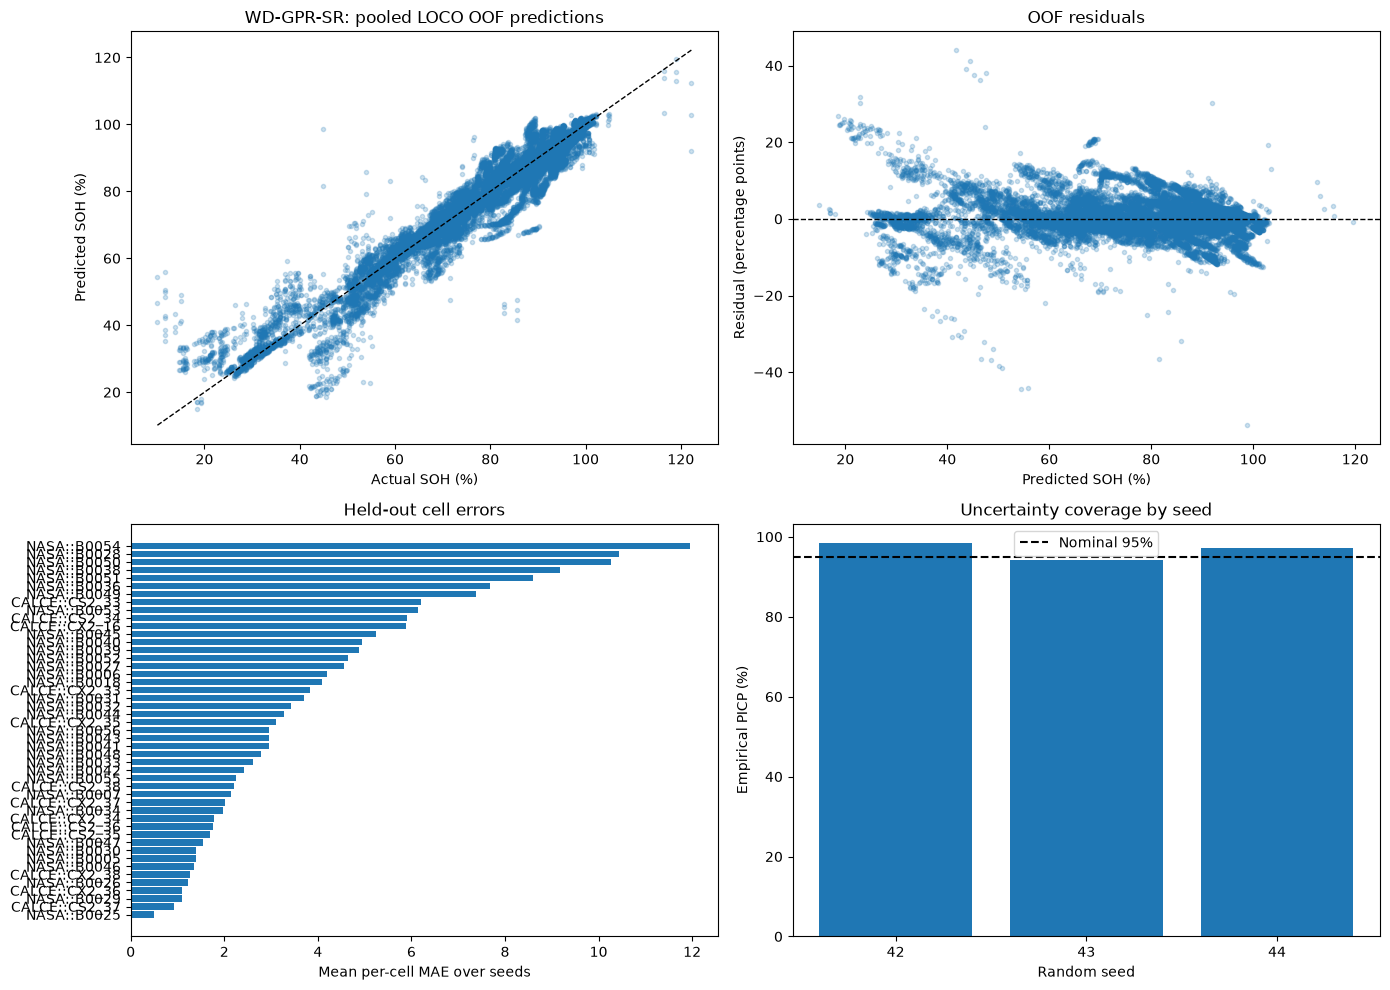

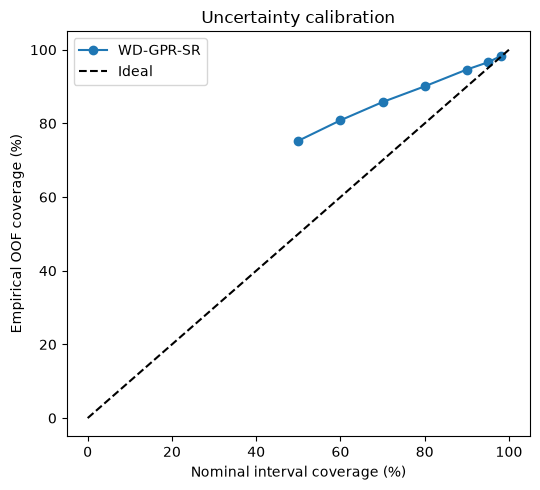

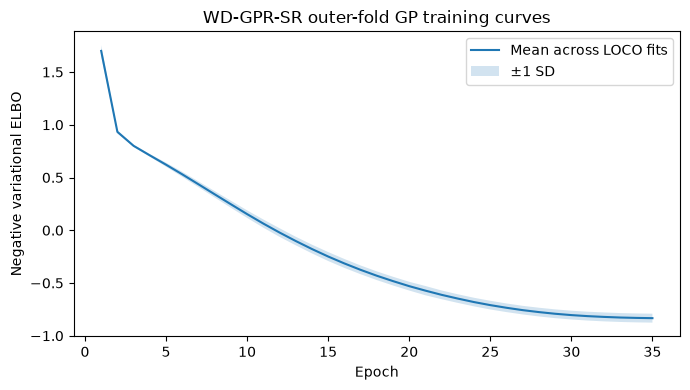

Saved LOCO diagnostic plots, calibration curve and training curve to /home/raj/Documents/Projects/PBL/WD-GPR-SR/results


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax = axes[0,0]
ax.scatter(oof['y_true_soh_pct'], oof['y_pred_soh_pct'], alpha=0.22, s=9)
lo = float(min(oof['y_true_soh_pct'].min(), oof['y_pred_soh_pct'].min()))
hi = float(max(oof['y_true_soh_pct'].max(), oof['y_pred_soh_pct'].max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1)
ax.set_xlabel('Actual SOH (%)'); ax.set_ylabel('Predicted SOH (%)'); ax.set_title('WD-GPR-SR: pooled LOCO OOF predictions')

ax = axes[0,1]
ax.scatter(oof['y_pred_soh_pct'], oof['residual'], alpha=0.22, s=9)
ax.axhline(0,color='black',linestyle='--',lw=1)
ax.set_xlabel('Predicted SOH (%)'); ax.set_ylabel('Residual (percentage points)'); ax.set_title('OOF residuals')

cell_mae = oof.groupby(['seed','cell_group'])['abs_error'].mean().groupby('cell_group').mean().sort_values()
ax = axes[1,0]
ax.barh(cell_mae.index.astype(str), cell_mae.values)
ax.set_xlabel('Mean per-cell MAE over seeds'); ax.set_title('Held-out cell errors')

ax = axes[1,1]
seed_means = oof.groupby('seed').apply(lambda g: calculate_metrics(g.y_true_soh_pct,g.y_pred_soh_pct,g.y_std_soh_pct)['PICP_95_pct'])
ax.bar(seed_means.index.astype(str), seed_means.values)
ax.axhline(95,color='black',linestyle='--',label='Nominal 95%')
ax.set_xlabel('Random seed'); ax.set_ylabel('Empirical PICP (%)'); ax.set_title('Uncertainty coverage by seed'); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS_DIR/'loco_diagnostics.png',dpi=180); plt.show()

coverage_rows=[]
for nominal in [50,60,70,80,90,95,98]:
    z = float(__import__('scipy').stats.norm.ppf((1+nominal/100)/2))
    empirical = np.mean(np.abs(oof['y_true_soh_pct'].to_numpy()-oof['y_pred_soh_pct'].to_numpy()) <= z*oof['y_std_soh_pct'].to_numpy())*100
    coverage_rows.append({'nominal_coverage_pct':nominal,'empirical_coverage_pct':empirical})
coverage_df=pd.DataFrame(coverage_rows)
coverage_df.to_csv(RESULTS_DIR/'uncertainty_calibration_curve.csv',index=False)
plt.figure(figsize=(5.5,5))
plt.plot(coverage_df.nominal_coverage_pct,coverage_df.empirical_coverage_pct,'o-',label='WD-GPR-SR')
plt.plot([0,100],[0,100],'k--',label='Ideal')
plt.xlabel('Nominal interval coverage (%)'); plt.ylabel('Empirical OOF coverage (%)')
plt.title('Uncertainty calibration'); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR/'uncertainty_calibration.png',dpi=180); plt.show()

if not training_loss_history.empty:
    curve = training_loss_history.groupby('epoch')['negative_ELBO'].agg(['mean','std']).reset_index()
    plt.figure(figsize=(7,4))
    plt.plot(curve['epoch'], curve['mean'], label='Mean across LOCO fits')
    if curve['std'].notna().any():
        plt.fill_between(curve['epoch'], curve['mean']-curve['std'].fillna(0),
                         curve['mean']+curve['std'].fillna(0), alpha=0.2, label='±1 SD')
    plt.xlabel('Epoch'); plt.ylabel('Negative variational ELBO')
    plt.title('WD-GPR-SR outer-fold GP training curves'); plt.legend()
    plt.tight_layout(); plt.savefig(RESULTS_DIR/'training_curve.png',dpi=180); plt.show()
    curve.to_csv(RESULTS_DIR/'training_curve_summary.csv',index=False)

print('Saved LOCO diagnostic plots, calibration curve and training curve to', RESULTS_DIR)


## 9. Ablation study

The ablations remove or replace one component at a time on identical outer LOCO test cells and seeds:

- **WD-GP without SR:** remove symbolic residual correction.
- **WD-GP + unweighted SR:** retain a symbolic residual equation but remove its uncertainty input and uncertainty-weighted fitness.
- **Wide-only sparse GP:** remove the deep covariance branch.
- **Deep-only sparse GP:** remove the wide linear covariance branch.

Branch-only models are point-prediction ablations; uncertainty metrics are intentionally blank because their calibration residuals were not separately estimated. Full-model and symbolic-stage ablations report the uncertainty metrics.

Ablation summary (means across seeds; fold-level values retained in ablation_fold_metrics.csv):


,variant,MAE_mean,MAE_std,MSE_mean,MSE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,MAPE_pct_mean,MAPE_pct_std,NLL_mean,NLL_std,PICP_95_pct_mean,PICP_95_pct_std,MPIW_95_mean,MPIW_95_std
3,WD-GP without symbolic residual,3.811684,0.239504,31.839432,4.918800,4.524683,0.213883,-4.202798,4.358504,6.847061,0.319469,3.187078,0.033331,95.104879,0.886168,26.693758,0.434452
0,Deep-only sparse GP,3.842941,0.205905,30.117571,3.205945,4.574526,0.196414,-1.599649,1.442617,6.881741,0.379708,NaN,NaN,NaN,NaN,NaN,NaN
1,Full WD-GPR-SR,3.909611,0.194535,33.983873,5.378766,4.632717,0.213683,-4.202915,4.296450,7.096105,0.361237,3.202475,0.058792,94.237739,1.354420,26.409071,0.430769
2,WD-GP + unweighted SR (no uncertainty input/we...,3.996807,0.229473,34.945571,5.735384,4.715857,0.240520,-4.285226,4.322677,7.233535,0.429495,3.212831,0.057907,94.264336,1.428475,26.415869,0.363213
4,Wide-only sparse GP,6.846608,0.029248,88.950301,0.862725,8.019015,0.026752,-12.337728,0.263910,12.065527,0.076993,NaN,NaN,NaN,NaN,NaN,NaN


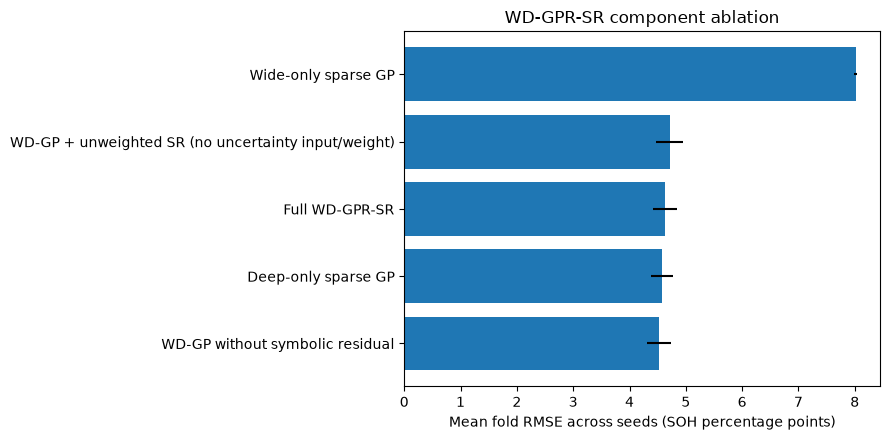

In [20]:
abl_summary_rows=[]
for variant, g in ablation_fold_metrics.groupby('variant'):
    by_seed=[]
    for seed, gs in g.groupby('seed'):
        if gs['NLL'].notna().all():
            by_seed.append({'seed':seed, **{m:gs[m].mean() for m in ['MAE','MSE','RMSE','R2','MAPE_pct','NLL','PICP_95_pct','MPIW_95']}})
        else:
            by_seed.append({'seed':seed, **{m:gs[m].mean() for m in ['MAE','MSE','RMSE','R2','MAPE_pct']}, 'NLL':np.nan,'PICP_95_pct':np.nan,'MPIW_95':np.nan})
    seed_df=pd.DataFrame(by_seed)
    row={'variant':variant}
    for metric in ['MAE','MSE','RMSE','R2','MAPE_pct','NLL','PICP_95_pct','MPIW_95']:
        row[f'{metric}_mean']=seed_df[metric].mean()
        row[f'{metric}_std']=seed_df[metric].std(ddof=1) if seed_df[metric].notna().sum()>1 else np.nan
    abl_summary_rows.append(row)
ablation_summary=pd.DataFrame(abl_summary_rows).sort_values('RMSE_mean',na_position='last')
ablation_summary.to_csv(RESULTS_DIR/'ablation_summary.csv',index=False)
print('Ablation summary (means across seeds; fold-level values retained in ablation_fold_metrics.csv):')
display(ablation_summary)

plot_df=ablation_summary.dropna(subset=['RMSE_mean'])
plt.figure(figsize=(9,4.5))
plt.barh(plot_df['variant'],plot_df['RMSE_mean'],xerr=plot_df['RMSE_std'].fillna(0))
plt.xlabel('Mean fold RMSE across seeds (SOH percentage points)')
plt.title('WD-GPR-SR component ablation')
plt.tight_layout(); plt.savefig(RESULTS_DIR/'ablation_rmse.png',dpi=180); plt.show()

paired=[]
for metric in ['MAE','RMSE','R2','NLL','PICP_95_pct','MPIW_95']:
    for variant in ['Full WD-GPR-SR','WD-GP without symbolic residual','WD-GP + unweighted SR (no uncertainty input/weight)']:
        g=ablation_fold_metrics[ablation_fold_metrics.variant==variant]
        paired.append({'metric':metric,'variant':variant,'mean':g[metric].mean(),'std':g[metric].std(ddof=1)})
paired_ablation=pd.DataFrame(paired)
paired_ablation.to_csv(RESULTS_DIR/'ablation_metric_detail.csv',index=False)


## 10. Final all-data inference fit and artifact save

The final bundle is trained on all labelled cells only **after** the three-seed LOCO evaluation. Its metrics are not used as test metrics. The saved bundle contains the train-fitted preprocessor, target scaler, sparse-GP state, inducing points and symbolic equation. `predict_new_cycle_rows()` accepts the same cycle-level rows as `unified.parquet`, not raw point-by-point telemetry.

In [21]:
FINAL_SEED = RUN_SEEDS[0]
set_seed(FINAL_SEED)
final_preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
X_all_2d = np.asarray(final_preprocessor.fit_transform(cycles[FEATURE_COLUMNS]), dtype=np.float32)
final_target_scaler = StandardScaler().fit(cycles[[TARGET]])
y_all_scaled = final_target_scaler.transform(cycles[[TARGET]]).ravel().astype(np.float32)
final_fit = fit_wd_gpr_sr(
    X_all_2d, y_all_scaled, cycles['cell_group'].astype(str).to_numpy(),
    final_preprocessor.get_feature_names_out().tolist(), seed=FINAL_SEED + 50001
)

FEATURE_NAMES_TRANSFORMED = final_preprocessor.get_feature_names_out().tolist()
FINAL_EQUATION_FEATURE_NAMES = [FEATURE_NAMES_TRANSFORMED[i] for i in final_fit['symbolic_feature_indices']]
if final_fit['symbolic_tree'].get('args'):
    FINAL_EQUATION_INPUT_NAMES = FINAL_EQUATION_FEATURE_NAMES + ['normalized_gp_uncertainty']
else:
    FINAL_EQUATION_INPUT_NAMES = FINAL_EQUATION_FEATURE_NAMES + ['normalized_gp_uncertainty']
FINAL_EQUATION_TEXT = tree_expression(final_fit['symbolic_tree'], FINAL_EQUATION_INPUT_NAMES)


def predict_final_scaled(X):
    return predict_wd_gpr_sr(final_fit, np.asarray(X,dtype=np.float32))


def predict_final_soh(X):
    pred_s, std_s, *_ = predict_final_scaled(X)
    pred = final_target_scaler.inverse_transform(pred_s.reshape(-1,1)).ravel()
    return pred


def predict_new_cycle_rows(new_cycles, bundle=None):
    bundle = bundle or final_bundle
    required = set(bundle['feature_columns']) | {'source_dataset','entity_id','cycle_id','cycle_order'}
    missing = required - set(new_cycles.columns)
    if missing:
        raise ValueError(f'Inference cycle rows missing required fields: {sorted(missing)}')
    frame = new_cycles.copy()
    frame['source_dataset'] = frame['source_dataset'].astype('string').str.strip().str.upper()
    frame['entity_id'] = frame['entity_id'].astype('string').str.strip()
    frame['cycle_id'] = frame['cycle_id'].astype('string').str.strip()
    frame['cycle_order'] = pd.to_numeric(frame['cycle_order'],errors='coerce')
    if frame['cycle_order'].isna().any():
        raise ValueError('cycle_order must be finite numeric at inference.')
    frame['cell_group'] = frame['source_dataset'].astype(str) + '::' + frame['entity_id'].astype(str)
    frame['cycle_index'] = frame['cycle_order'].astype(float)
    frame = frame.sort_values(['source_dataset','entity_id','cycle_order','cycle_id'],kind='mergesort').reset_index(drop=True)
    X = np.asarray(bundle['preprocessor'].transform(frame[bundle['feature_columns']]),dtype=np.float32)
    gp_model, likelihood = build_gp_from_bundle(bundle, device=DEVICE)
    gp_mean, gp_std = predict_gp_distribution(gp_model, likelihood, X)
    sr_X = make_symbolic_inputs(X,gp_std,bundle['symbolic_feature_indices'],bundle['uncertainty_scale'],True)
    correction = evaluate_symbolic_tree(bundle['symbolic_tree'],sr_X)
    pred_s = gp_mean + correction
    std_s = np.sqrt(gp_std**2 + float(bundle['symbolic_residual_std_scaled'])**2)
    pred = bundle['target_scaler'].inverse_transform(pred_s.reshape(-1,1)).ravel()
    std = std_s * float(bundle['target_scaler'].scale_[0])
    out = frame[['source_dataset','entity_id','cycle_id','cycle_order','cell_group']].copy()
    out['predicted_soh_pct'] = pred
    out['predictive_std_soh_pct'] = std
    return out


def build_gp_from_bundle(bundle, device='cpu'):
    inducing = torch.as_tensor(bundle['inducing_points'],dtype=torch.float32,device=device)
    cfg = bundle['gp_config']
    model = WideDeepSparseGP(inducing, input_dim=cfg['input_dim'], latent_dim=cfg['latent_dim'], kernel_mode=cfg['kernel_mode']).to(device)
    likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
    model.load_state_dict(bundle['gp_state_dict'])
    likelihood.load_state_dict(bundle['likelihood_state_dict'])
    model.eval(); likelihood.eval()
    return model, likelihood


def state_dict_to_cpu(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

ARTIFACT_PATH = MODEL_DIR / 'wd_gpr_sr.joblib'
final_bundle = {
    'format_version': 2, 'model_name': 'wd_gpr_sr', 'target': TARGET,
    'seed': FINAL_SEED, 'run_seeds': list(RUN_SEEDS),
    'numeric_features': list(NUMERIC_FEATURES),
    'categorical_features': list(CATEGORICAL_FEATURES),
    'feature_columns': list(FEATURE_COLUMNS),
    'feature_names_transformed': list(FEATURE_NAMES_TRANSFORMED),
    'preprocessor': final_preprocessor, 'target_scaler': final_target_scaler,
    'gp_config': {'input_dim': int(X_all_2d.shape[1]), 'latent_dim': LATENT_DIM, 'kernel_mode':'wide_deep'},
    'inducing_points': final_fit['gp_model'].variational_strategy.inducing_points.detach().cpu(),
    'gp_state_dict': state_dict_to_cpu(final_fit['gp_model']),
    'likelihood_state_dict': state_dict_to_cpu(final_fit['likelihood']),
    'symbolic_tree': final_fit['symbolic_tree'],
    'symbolic_feature_indices': final_fit['symbolic_feature_indices'].tolist(),
    'symbolic_feature_names': FINAL_EQUATION_FEATURE_NAMES,
    'uncertainty_scale': float(final_fit['uncertainty_scale']),
    'symbolic_residual_std_scaled': float(final_fit['symbolic_residual_std_scaled']),
    'gp_residual_std_scaled': float(final_fit['gp_residual_std_scaled']),
    'symbolic_status': final_fit['symbolic_status'],
    'equation_node_count': int(final_fit['equation_node_count']),
    'final_fit_time_s': float(final_fit['fit_time_s']),
    'equation_text': FINAL_EQUATION_TEXT,
    'training_cells': list(CELL_GROUPS), 'training_cycle_count': int(len(cycles)),
    'training_note': 'Final inference model refit on all labelled NASA/CALCE cycles after 3-seed LOCO evaluation.',
}
joblib.dump(final_bundle, ARTIFACT_PATH, compress=3)
artifact_size_mb = ARTIFACT_PATH.stat().st_size/(1024**2)
print('Saved final inference bundle:', ARTIFACT_PATH)
print('Artifact size (MB):', round(artifact_size_mb,3))
print('Symbolic status:', final_fit['symbolic_status'])
print('Equation node count:', final_fit['equation_node_count'])
print('Residual equation (scaled SOH):', FINAL_EQUATION_TEXT)

with open(RESULTS_DIR/'symbolic_equation.json','w',encoding='utf-8') as f:
    json.dump(final_fit['symbolic_tree'],f,indent=2)
(RESULTS_DIR/'symbolic_equation.txt').write_text('SOH_scaled = GP_mean_scaled + r(x, normalized_GP_uncertainty)\n'+FINAL_EQUATION_TEXT+'\n',encoding='utf-8')


Saved final inference bundle: /home/raj/Documents/Projects/PBL/models/wd_gpr_sr.joblib
Artifact size (MB): 0.034
Symbolic status: gplearn_ok
Equation node count: 2
Residual equation (scaled SOH): (-(-0.06109445307))


82

## 11. Explainability and explanation consistency

Implemented methods:
- **SHAP** permutation explanations on the final all-data fit.
- **LIME** local surrogate for a representative cycle.
- **PDP** and **ICE** curves for selected transformed features.
- **ARD** length-scale relevance for the deep branch's learned latent dimensions (not misrepresented as direct raw-feature length scales).
- **Symbolic equation sensitivities** \(\partial r/\partial x\), estimated by finite differences.
- **Wide-branch projection relevance** and **rank consistency** of held-out-cell permutation explanations across the three random seeds.

The model is fitted on all labelled cycles for this final explanatory analysis. Predictive performance remains based exclusively on outer LOCO OOF predictions.

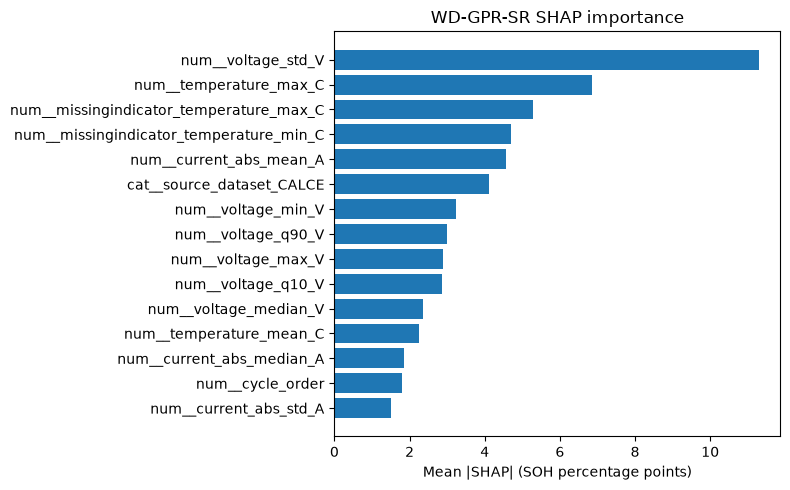

,feature_rule,local_weight
0,num__current_abs_mean_A <= -1.02,-14.158103
1,num__cycle_order <= -0.64,11.084027
2,num__voltage_std_V <= -0.74,10.114064
3,num__temperature_max_C <= 0.10,-9.952300
4,num__voltage_q90_V > 0.72,7.718896
5,0.00 < cat__source_dataset_CALCE <= 1.00,-7.414315
6,num__temperature_mean_C <= 0.17,5.919896
7,-1.18 < num__missingindicator_temperature_max_...,4.659834
8,num__temperature_std_C <= -0.10,3.927269
9,num__current_abs_median_A <= -0.73,-3.415890


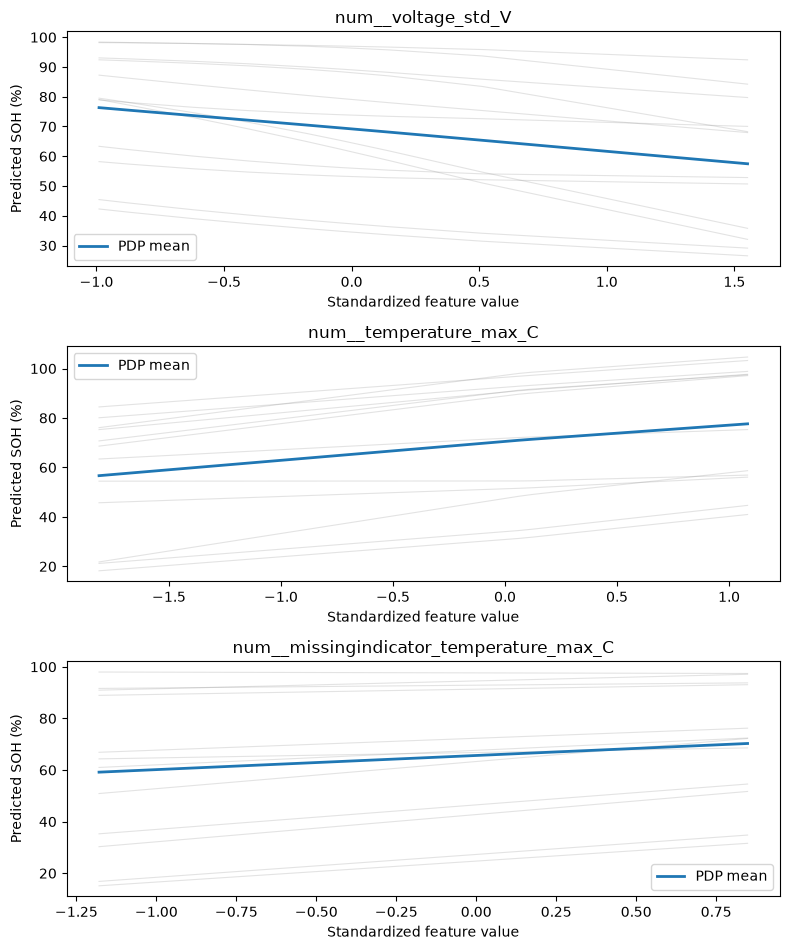

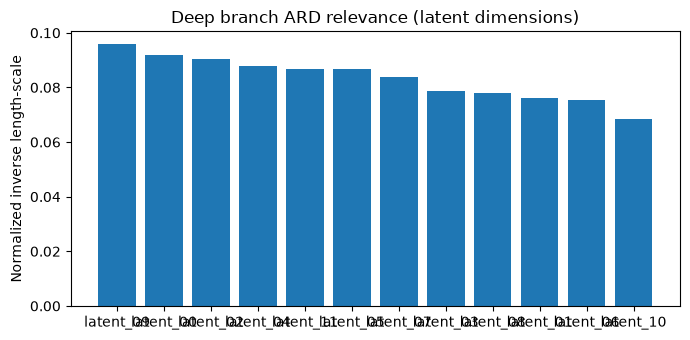

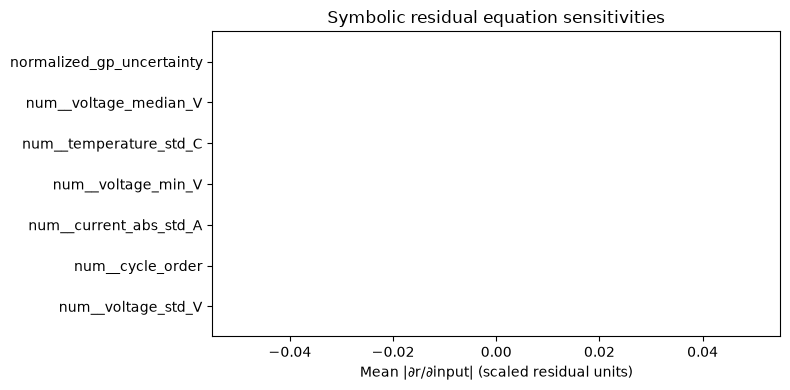

XAI summary:


,method,status,detail
0,SHAP,ok,Permutation SHAP on final all-data fit; explan...
1,LIME,ok,One local surrogate explanation on a represent...
2,PDP,ok,Mean prediction curves for selected transforme...
3,ICE,ok,Individual curves for 12 representative cycles.
4,ARD length-scale relevance,ok,"Relevance is for learned latent dimensions, no..."
5,Symbolic equation sensitivities,ok,Finite-difference sensitivities of the discove...


Explanation-consistency rank correlations:


,seed_a,seed_b,spearman_rank_correlation
0,42,43,0.973451
1,42,44,0.964602
2,43,44,0.955752


In [22]:
feature_names_xai = list(FEATURE_NAMES_TRANSFORMED)
rng = np.random.default_rng(RANDOM_SEED)
xai_status = []

shap_table = pd.DataFrame(columns=['feature','mean_abs_SHAP'])
try:
    import shap
    bg_idx = rng.choice(len(X_all_2d), min(24,len(X_all_2d)), replace=False)
    ex_idx = rng.choice(len(X_all_2d), min(6,len(X_all_2d)), replace=False)
    explainer = shap.PermutationExplainer(predict_final_soh, X_all_2d[bg_idx])
    shap_values = explainer(X_all_2d[ex_idx], max_evals=2*X_all_2d.shape[1]+1)
    sv = np.asarray(shap_values.values)
    if sv.ndim == 3: sv = sv.mean(axis=-1)
    shap_table = pd.DataFrame({'feature':feature_names_xai,'mean_abs_SHAP':np.mean(np.abs(sv),axis=0)}).sort_values('mean_abs_SHAP',ascending=False)
    shap_table.to_csv(XAI_DIR/'shap_importance.csv',index=False)
    top=shap_table.head(15).sort_values('mean_abs_SHAP')
    plt.figure(figsize=(8,5)); plt.barh(top.feature,top.mean_abs_SHAP)
    plt.xlabel('Mean |SHAP| (SOH percentage points)'); plt.title('WD-GPR-SR SHAP importance')
    plt.tight_layout(); plt.savefig(XAI_DIR/'shap_importance.png',dpi=180); plt.show()
    xai_status.append({'method':'SHAP','status':'ok','detail':'Permutation SHAP on final all-data fit; explanatory, not test metrics.'})
except Exception as exc:
    print('SHAP unavailable:',repr(exc))
    xai_status.append({'method':'SHAP','status':'unavailable','detail':str(exc)[:200]})

lime_table = pd.DataFrame(columns=['feature_rule','local_weight'])
try:
    from lime.lime_tabular import LimeTabularExplainer
    lime_bg = X_all_2d[rng.choice(len(X_all_2d),min(100,len(X_all_2d)),replace=False)]
    lime_exp = LimeTabularExplainer(lime_bg,feature_names=feature_names_xai,mode='regression',
                                    discretize_continuous=True,random_state=RANDOM_SEED)
    lime_local = lime_exp.explain_instance(X_all_2d[0],predict_final_soh,num_features=min(15,len(feature_names_xai)),num_samples=1500)
    lime_table = pd.DataFrame(lime_local.as_list(),columns=['feature_rule','local_weight'])
    lime_table.to_csv(XAI_DIR/'lime_local_explanation.csv',index=False)
    display(lime_table)
    xai_status.append({'method':'LIME','status':'ok','detail':'One local surrogate explanation on a representative cycle.'})
except Exception as exc:
    print('LIME unavailable:',repr(exc))
    xai_status.append({'method':'LIME','status':'unavailable','detail':str(exc)[:200]})

if not shap_table.empty:
    selected_xai_features = [feature_names_xai.index(x) for x in shap_table.head(3).feature]
else:
    selected_xai_features = np.argsort(np.nanvar(X_all_2d,axis=0))[::-1][:3].tolist()
pdp_rows=[]
local_idx=rng.choice(len(X_all_2d),min(12,len(X_all_2d)),replace=False)
fig,axes=plt.subplots(len(selected_xai_features),1,figsize=(8,3.2*len(selected_xai_features)),squeeze=False)
for ax,j in zip(axes.ravel(),selected_xai_features):
    vals=np.unique(np.quantile(X_all_2d[:,j],np.linspace(.1,.9,9)))
    if len(vals)<2:
        ax.set_visible(False); continue
    curves=[]
    for row in X_all_2d[local_idx]:
        varied=np.repeat(row.reshape(1,-1),len(vals),axis=0); varied[:,j]=vals
        curves.append(predict_final_soh(varied))
    curves=np.asarray(curves)
    for curve in curves: ax.plot(vals,curve,color='gray',alpha=.22,linewidth=.8)
    mean_curve=curves.mean(axis=0)
    ax.plot(vals,mean_curve,linewidth=2,label='PDP mean')
    ax.set_title(feature_names_xai[j]); ax.set_xlabel('Standardized feature value'); ax.set_ylabel('Predicted SOH (%)'); ax.legend()
    for v,m in zip(vals,mean_curve): pdp_rows.append({'feature':feature_names_xai[j],'feature_value':v,'pdp_mean_soh_pct':m})
fig.tight_layout(); fig.savefig(XAI_DIR/'pdp_ice.png',dpi=180); plt.show()
pd.DataFrame(pdp_rows).to_csv(XAI_DIR/'pdp_ice.csv',index=False)
xai_status.append({'method':'PDP','status':'ok','detail':'Mean prediction curves for selected transformed features.'})
xai_status.append({'method':'ICE','status':'ok','detail':'Individual curves for 12 representative cycles.'})

try:
    ard = final_fit['gp_model'].deep_kernel.base_kernel.lengthscale.detach().cpu().numpy().reshape(-1)
    ard_rel = 1.0/np.maximum(ard,1e-8)
    ard_rel = ard_rel/ard_rel.sum()
    ard_table=pd.DataFrame({'latent_dimension':[f'latent_{i:02d}' for i in range(len(ard))],
                            'lengthscale':ard,'inverse_lengthscale_relevance':ard_rel}).sort_values('inverse_lengthscale_relevance',ascending=False)
    ard_table.to_csv(XAI_DIR/'deep_ard_lengthscales.csv',index=False)
    plt.figure(figsize=(7,3.5)); plt.bar(ard_table.latent_dimension,ard_table.inverse_lengthscale_relevance)
    plt.ylabel('Normalized inverse length-scale'); plt.title('Deep branch ARD relevance (latent dimensions)')
    plt.tight_layout(); plt.savefig(XAI_DIR/'deep_ard_relevance.png',dpi=180); plt.show()
    xai_status.append({'method':'ARD length-scale relevance','status':'ok','detail':'Relevance is for learned latent dimensions, not a direct raw-feature ranking.'})
except Exception as exc:
    print('ARD extraction unavailable:',repr(exc))
    xai_status.append({'method':'ARD length-scale relevance','status':'unavailable','detail':str(exc)[:200]})

wide_w=final_fit['gp_model'].wide_branch.weight.detach().cpu().numpy()
wide_imp=np.linalg.norm(wide_w,axis=0)
wide_imp=wide_imp/max(float(wide_imp.sum()),1e-12)
wide_table=pd.DataFrame({'feature':feature_names_xai,'wide_projection_relevance':wide_imp}).sort_values('wide_projection_relevance',ascending=False)
wide_table.to_csv(XAI_DIR/'wide_branch_relevance.csv',index=False)

sel=final_fit['symbolic_feature_indices']
unc_scale=final_fit['uncertainty_scale']
base_X=X_all_2d[rng.choice(len(X_all_2d),min(100,len(X_all_2d)),replace=False)]
base_gp_mean,base_gp_std=predict_gp_distribution(final_fit['gp_model'],final_fit['likelihood'],base_X)
base_sr_X=make_symbolic_inputs(base_X,base_gp_std,sel,unc_scale,True)
sens_rows=[]
for j in range(base_sr_X.shape[1]):
    step=1e-3
    plus=base_sr_X.copy(); minus=base_sr_X.copy()
    plus[:,j]+=step; minus[:,j]-=step
    deriv=(evaluate_symbolic_tree(final_fit['symbolic_tree'],plus)-evaluate_symbolic_tree(final_fit['symbolic_tree'],minus))/(2*step)
    sens_rows.append({'symbolic_input':(FINAL_EQUATION_INPUT_NAMES[j] if j<len(FINAL_EQUATION_INPUT_NAMES) else f'x{j}'),
                      'mean_abs_d_residual_d_input':float(np.mean(np.abs(deriv))),
                      'median_abs_d_residual_d_input':float(np.median(np.abs(deriv)))})
sensitivity_table=pd.DataFrame(sens_rows).sort_values('mean_abs_d_residual_d_input',ascending=False)
sensitivity_table.to_csv(XAI_DIR/'symbolic_residual_sensitivities.csv',index=False)
plt.figure(figsize=(8,4)); p=sensitivity_table.sort_values('mean_abs_d_residual_d_input')
plt.barh(p.symbolic_input,p.mean_abs_d_residual_d_input)
plt.xlabel('Mean |∂r/∂input| (scaled residual units)'); plt.title('Symbolic residual equation sensitivities')
plt.tight_layout(); plt.savefig(XAI_DIR/'symbolic_sensitivities.png',dpi=180); plt.show()
xai_status.append({'method':'Symbolic equation sensitivities','status':'ok','detail':'Finite-difference sensitivities of the discovered residual equation.'})

perm_seed = permutation_importance.groupby(['seed','feature'])['permutation_MAE_increase'].mean().unstack('feature')
perm_seed.to_csv(XAI_DIR/'permutation_importance_by_seed.csv')
consistency_rows=[]
for i, s1 in enumerate(perm_seed.index):
    for s2 in perm_seed.index[i+1:]:
        a=perm_seed.loc[s1].fillna(0); b=perm_seed.loc[s2].fillna(0)
        rho=float(spearmanr(a,b).statistic) if len(a)>1 else np.nan
        consistency_rows.append({'seed_a':int(s1),'seed_b':int(s2),'spearman_rank_correlation':rho})
consistency=pd.DataFrame(consistency_rows)
consistency.to_csv(XAI_DIR/'explanation_consistency.csv',index=False)

xai_summary=pd.DataFrame(xai_status)
xai_summary.to_csv(XAI_DIR/'xai_summary.csv',index=False)
print('XAI summary:')
display(xai_summary)
print('Explanation-consistency rank correlations:')
display(consistency)


## 12. Baseline comparison, reproducibility manifest and final summary

In [26]:
BASELINE_RESULTS_DIR = PROJECT_ROOT/'baseline_results'
comparison_rows=[]
for model_dir in sorted(BASELINE_RESULTS_DIR.iterdir()) if BASELINE_RESULTS_DIR.is_dir() else []:
    metric_file=model_dir/'metrics.json'
    if not metric_file.is_file(): continue
    try:
        m=json.loads(metric_file.read_text(encoding='utf-8'))
        comparison_rows.append({'model':m.get('model',model_dir.name),'MAE':m.get('MAE',np.nan),
            'RMSE':m.get('RMSE',np.nan),'R2':m.get('R2',np.nan),'MAPE_pct':m.get('MAPE_pct',np.nan),
            'NLL':m.get('NLL',np.nan),'PICP_95_pct':m.get('PICP_95_pct',np.nan),'MPIW_95':m.get('MPIW_95',np.nan),
            'result_scope':'single-seed baseline OOF'})
    except Exception as exc:
        print('Could not read',metric_file,':',exc)

comparison_rows.append({'model':'WD-GPR-SR','MAE':seed_metrics.MAE[0],
    'RMSE':seed_metrics.RMSE[0],'R2':seed_metrics.R2[0],'MAPE_pct':seed_metrics.MAPE_pct[0],
    'NLL':seed_metrics.NLL[0],'PICP_95_pct':seed_metrics.PICP_95_pct[0],'MPIW_95':seed_metrics.MPIW_95[0],
    'result_scope':'3-seed LOCO mean; see metrics_mean_std.csv'})
baseline_comparison=pd.DataFrame(comparison_rows)
if not baseline_comparison.empty:
    baseline_comparison=baseline_comparison.sort_values('RMSE',na_position='last').reset_index(drop=True)
    baseline_comparison.insert(0,'RMSE_rank',np.arange(1,len(baseline_comparison)+1))
    baseline_comparison.to_csv(RESULTS_DIR/'baseline_comparison.csv',index=False)
    display(baseline_comparison)
else:
    print('No baseline metrics.json files found; run baseline notebooks first.')

run_manifest={
    'model':'WD-GPR-SR','target':TARGET,'seeds':SEEDS_TO_RUN,
    'outer_protocol':'sorted-cell LOCO, identical cell groups/fold numbers as baseline notebooks',
    'inner_protocol':f'{CROSSFIT_FOLDS}-fold GroupKFold on outer-training cells for cross-fitted GP residuals; disjoint group calibration subset for symbolic residual sigma',
    'numeric_features':NUMERIC_FEATURES,'categorical_features':CATEGORICAL_FEATURES,
    'batch_size':BATCH_SIZE,'latent_dim':LATENT_DIM,'inducing_points':NUM_INDUCING,
    'inner_gp_epochs':INNER_GP_EPOCHS,'final_gp_epochs':FINAL_GP_EPOCHS,
    'sr_population_size':SR_POPULATION_SIZE,'sr_generations':SR_GENERATIONS,
    'symbolic_uncertainty_weight':'clip(median_gp_std / (gp_std + 1e-4), 0.25, 4.0)',
    'smoke_test':SMOKE_TEST,
    'note':'Baseline metrics currently use the baseline notebook seed (typically 42); WD-GPR-SR reports 3 seeds as specified by the PDF. For a strictly matched multi-seed model comparison, rerun all baseline notebooks with the same three seeds.'
}
(RESULTS_DIR/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2,default=str),encoding='utf-8')
with open(RESULTS_DIR/'final_summary.json','w',encoding='utf-8') as f:
    json.dump({'seed_metrics':seed_metrics.to_dict(orient='records'),
               'mean_std':metrics_mean_std.to_dict(orient='records'),
               'equation_node_count':int(final_fit['equation_node_count']),
               'final_fit_time_s':float(final_fit['fit_time_s']),
               'equation':FINAL_EQUATION_TEXT,
               'artifact_path':str(ARTIFACT_PATH),'artifact_size_MB':artifact_size_mb},f,indent=2,default=str)

print('Saved results to:',RESULTS_DIR)
print('Saved model to:',ARTIFACT_PATH)


,RMSE_rank,model,MAE,RMSE,R2,MAPE_pct,NLL,PICP_95_pct,MPIW_95,result_scope
0,1,svr,2.931901,4.330244,0.940372,4.780814,7.878259,57.446114,4.636614,single-seed baseline OOF
1,2,WD-GPR-SR,3.082017,4.406460,0.938255,5.060739,3.005550,98.318093,25.231952,3-seed LOCO mean; see metrics_mean_std.csv
2,3,deep_nn,3.063205,4.517042,0.935117,5.244156,6.643540,55.943828,5.237953,single-seed baseline OOF
3,4,wide_deep_nn,3.412901,4.695571,0.929886,5.577323,8.015462,48.987590,4.942986,single-seed baseline OOF
4,5,gpr_matern,3.004557,4.757481,0.928025,5.257813,3.388247,76.681907,14.304949,single-seed baseline OOF
5,6,wide_nn,3.366713,4.862811,0.924803,5.734281,7.236676,57.037884,5.565112,single-seed baseline OOF
6,7,bilstm,3.360621,4.877374,0.924352,5.557508,11.870564,47.256695,4.184577,single-seed baseline OOF
7,8,sparse_gpr,3.468995,4.988081,0.920879,5.680370,3.101653,82.544089,11.762986,single-seed baseline OOF
8,9,deep_kernel_gpr,3.571207,5.264663,0.911861,5.872440,3.243707,99.395820,33.410818,single-seed baseline OOF
9,10,xgboost,4.027127,6.232313,0.876484,7.230915,10.905449,52.106466,5.628311,single-seed baseline OOF


Saved results to: /home/raj/Documents/Projects/PBL/WD-GPR-SR/results
Saved model to: /home/raj/Documents/Projects/PBL/models/wd_gpr_sr.joblib


## 13. Edge component export for Jetson Orin Nano

The PDF specifically calls for exporting the deep feature extractor to TensorRT, storing sparse-GP inducing points as arrays and compiling the discovered equation to C. This cell saves both learned branch ONNX files, inducing points, full GP/likelihood state dictionaries, kernel parameters and the equation in JSON/C. **Build TensorRT engines on the Jetson**, not on the laptop. The generated metadata is an export contract; validate the complete edge predictor against the Python model before reporting deployment results.

In [24]:
EDGE_DIR = MODEL_DIR/'optimized'/'wd_gpr_sr'
EDGE_DIR.mkdir(parents=True,exist_ok=True)

torch.save(state_dict_to_cpu(final_fit['gp_model']),EDGE_DIR/'gp_state_dict.pt')
torch.save(state_dict_to_cpu(final_fit['likelihood']),EDGE_DIR/'likelihood_state_dict.pt')
np.save(EDGE_DIR/'inducing_points.npy',final_fit['gp_model'].variational_strategy.inducing_points.detach().cpu().numpy())

edge_onnx_status={}
example=torch.zeros((1,X_all_2d.shape[1]),dtype=torch.float32)
for branch_name, branch in [('wide_branch',final_fit['gp_model'].wide_branch),('deep_feature_extractor',final_fit['gp_model'].deep_branch)]:
    try:
        branch_export=copy.deepcopy(branch).to('cpu').eval()
        torch.onnx.export(branch_export,example,str(EDGE_DIR/f'{branch_name}.onnx'),
                          input_names=['input'],output_names=['output'],
                          dynamic_axes={'input':{0:'batch'},'output':{0:'batch'}},
                          opset_version=17,dynamo=False)
        edge_onnx_status[branch_name]='exported'
    except Exception as exc:
        edge_onnx_status[branch_name]=f'failed:{type(exc).__name__}:{str(exc)[:160]}'

with torch.no_grad():
    gp=final_fit['gp_model']
    edge_kernel_params={
        'latent_dim':LATENT_DIM,
        'deep_ard_lengthscale':gp.deep_kernel.base_kernel.lengthscale.detach().cpu().numpy().reshape(-1).tolist(),
        'deep_outputscale':float(gp.deep_kernel.outputscale.detach().cpu().reshape(-1)[0]),
        'wide_outputscale':float(gp.wide_kernel.outputscale.detach().cpu().reshape(-1)[0]),
        'mean_constant':float(gp.mean_module.constant.detach().cpu().reshape(-1)[0]),
        'likelihood_noise':float(final_fit['likelihood'].noise.detach().cpu().reshape(-1)[0]),
    }
(EDGE_DIR/'kernel_parameters.json').write_text(json.dumps(edge_kernel_params,indent=2),encoding='utf-8')

num_cfg = None
cat_cfg = None
if NUMERIC_FEATURES:
    num_pipe = final_preprocessor.named_transformers_['num']
    num_imp = num_pipe.named_steps['imputer']
    num_scaler = num_pipe.named_steps['scaler']
    num_cfg = {
        'imputer_statistics': np.asarray(num_imp.statistics_, dtype=float).tolist(),
        'indicator_features': np.asarray(getattr(num_imp.indicator_, 'features_', []), dtype=int).tolist(),
        'scaler_mean': np.asarray(num_scaler.mean_, dtype=float).tolist(),
        'scaler_scale': np.asarray(num_scaler.scale_, dtype=float).tolist(),
    }
if CATEGORICAL_FEATURES:
    cat_pipe = final_preprocessor.named_transformers_['cat']
    cat_imp = cat_pipe.named_steps['imputer']
    cat_encoder = cat_pipe.named_steps['onehot']
    cat_cfg = {
        'imputer_statistics': [str(x) for x in cat_imp.statistics_],
        'categories': [[str(v) for v in arr] for arr in cat_encoder.categories_],
    }
preprocessing_metadata = {
    'feature_columns': FEATURE_COLUMNS,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'transformed_feature_names': FEATURE_NAMES_TRANSFORMED,
    'numeric_preprocessing': num_cfg,
    'categorical_preprocessing': cat_cfg,
    'target_mean': float(final_target_scaler.mean_[0]),
    'target_scale': float(final_target_scaler.scale_[0]),
}
(EDGE_DIR/'preprocessing.json').write_text(json.dumps(preprocessing_metadata,indent=2),encoding='utf-8')

edge_input_names=FINAL_EQUATION_FEATURE_NAMES+['normalized_gp_uncertainty']
edge_expr=tree_expression(final_fit['symbolic_tree'], [])
c_src=f'''#include <math.h>\nstatic inline double pdiv(double a,double b){{return fabs(b)>1e-3?a/b:1.0;}}\nstatic inline double psqrt(double a){{return sqrt(fabs(a));}}\nstatic inline double plog(double a){{return fabs(a)>1e-3?log(fabs(a)):0.0;}}\n// Returns standardized residual correction; GP output is also in standardized SOH units.\ndouble wd_gpr_sr_residual(const double *x){{return {edge_expr};}}\n'''
(EDGE_DIR/'equation.c').write_text(c_src,encoding='utf-8')
(EDGE_DIR/'equation.json').write_text(json.dumps(final_fit['symbolic_tree'],indent=2),encoding='utf-8')
trt_script = f'''#!/usr/bin/env bash
set -euo pipefail
HERE=\"$(cd \"$(dirname \"${{BASH_SOURCE[0]}}\")\" && pwd)\"
command -v trtexec >/dev/null 2>&1 || {{ echo 'trtexec not found; use NVIDIA JetPack TensorRT tools.'; exit 1; }}
for name in wide_branch deep_feature_extractor; do
  trtexec --onnx=\"$HERE/${{name}}.onnx\" --saveEngine=\"$HERE/${{name}}.engine\" --fp16 \
    --minShapes=input:1x{X_all_2d.shape[1]} --optShapes=input:16x{X_all_2d.shape[1]} --maxShapes=input:128x{X_all_2d.shape[1]}
done
'''
(EDGE_DIR/'build_tensorrt_engines.sh').write_text(trt_script,encoding='utf-8')
os.chmod(EDGE_DIR/'build_tensorrt_engines.sh',0o755)

edge_metadata={
    'model_name':'wd_gpr_sr','format_version':1,'input_features':FEATURE_NAMES_TRANSFORMED,
    'transformed_input_dim':int(X_all_2d.shape[1]),
    'gp_config':{'input_dim':int(X_all_2d.shape[1]),'latent_dim':LATENT_DIM,'kernel_mode':'wide_deep'},
    'onnx_models':{'wide_branch':'wide_branch.onnx','deep_feature_extractor':'deep_feature_extractor.onnx'},
    'onnx_input_shape':[None,int(X_all_2d.shape[1])],
    'tensorrt_build_script':'build_tensorrt_engines.sh',
    'numeric_features':NUMERIC_FEATURES,'categorical_features':CATEGORICAL_FEATURES,
    'target_mean':float(final_target_scaler.mean_[0]),'target_scale':float(final_target_scaler.scale_[0]),
    'symbolic_feature_indices':final_fit['symbolic_feature_indices'].tolist(),
    'symbolic_feature_names':FINAL_EQUATION_FEATURE_NAMES,
    'uncertainty_scale':float(final_fit['uncertainty_scale']),
    'symbolic_residual_std_scaled':float(final_fit['symbolic_residual_std_scaled']),
    'equation_node_count':int(final_fit['equation_node_count']),
    'equation_c':'equation.c','equation_json':'equation.json','preprocessing_json':'preprocessing.json',
    'onnx_exports':edge_onnx_status,
    'note':'Inducing points and GP state are saved. A Jetson-side covariance/ONNX/TensorRT runner must apply the saved preprocessing and kernel equations; TensorRT engines are device-specific and are not built on the laptop.'
}
(EDGE_DIR/'metadata.json').write_text(json.dumps(edge_metadata,indent=2),encoding='utf-8')
print('Edge components written to:',EDGE_DIR)
print('ONNX export status:',edge_onnx_status)

if shutil.which('gcc'):
    try:
        subprocess.run(['gcc','-O3','-fPIC','-shared',str(EDGE_DIR/'equation.c'),'-o',str(EDGE_DIR/'equation.so'),'-lm'],check=True,capture_output=True,text=True)
        print('Compiled equation.so')
    except Exception as exc:
        print('C compilation unavailable:',exc)
else:
    print('gcc not found; equation.c is saved for compilation on Jetson.')


Edge components written to: /home/raj/Documents/Projects/PBL/models/optimized/wd_gpr_sr
ONNX export status: {'wide_branch': 'exported', 'deep_feature_extractor': 'exported'}
Compiled equation.so


/tmp/ipykernel_5289/217539944.py:17: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(branch_export,example,str(EDGE_DIR/f'{branch_name}.onnx'),
